# 데이터기반공학해석 (2026-2) — 과제 2회차 Part B: Koopman · eDMD

교재 Brunton & Kutz, *Data-Driven Science and Engineering* 2/e, §7.4–7.5  ·  W06 강의노트(10/6) 기준

| 문항 | 내용 | 필요한 데이터 |
|---|---|---|
| 1 | 교재 예제 재현: (7.82) 계의 데이터로 사전 D1–D4의 eDMD — 고유값·잔차 $r_j$·예측 오차(표 5, 그림 11) 재현, D4의 $\varphi_\lambda$ 계수를 (7.84)와 비교 + 손계산 예 0·2·4 검산 | 없음(해석해로 생성) |
| 2 | 배포 풀이 `w06_solution_bugs.m` 오류 찾기 — 6건: 위반한 식, 수정 코드, 수정 전후 수치 | `w06_solution_bugs.m` (노트북 폴더) |
| 3 | 개인 탐구: 정전 구동 CNT 공진기(연구 모델)의 과도응답에 eDMD — 사전 4가지, 고유값·$r_j$·새 초기조건 예측, 가짜 고유쌍 가려내기, 닫히지 않는 항 추정, §2.5의 한계(여러 끌개) 확인; Koopman 고유값을 연구의 Hill–Floquet 지수와 대조 | `result_0819/…AC_0.19…_matlab_floquet_stability.csv`, `…HBM_coeffs_branch02.csv` (Floquet 대조·isola 초기조건용) |



In [1]:
# 공통 환경 설정 ---------------------------------------------------------
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
import os, warnings, itertools
warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.family": "DejaVu Sans"})
pd.set_option("display.float_format", lambda v: f"{v:.4g}")

DATA_DIR = Path(os.environ.get("ISOLA_DIR", Path.home() / "Desktop" / "Isola" / "deflated_continuation" / "result_0819"))
print("result_0819 :", DATA_DIR, "(exists)" if DATA_DIR.exists() else "(NOT FOUND — 문제 3의 Floquet 대조·isola 초기조건에 필요)")


result_0819 : C:\Users\smsm0\Desktop\Isola\deflated_continuation\result_0819 (exists)


## 0. 6주차 정리 — "상태 대신 측정값을 따라가면 비선형계가 선형이 된다"

### 0.1 큰 그림 [B&K §7.4 도입]
* 상태 $x$를 직접 따라가지 않고, $x$에서 잴 수 있는 모든 **관측함수** $g(x)$의 공간(함수들의 벡터공간, Hilbert 공간)을 본다 → 그 공간에서는 비선형 동역학이 **무한차원의 선형 연산자**(Koopman 연산자)가 된다 → 데이터로 유한 행렬로 근사한다.
* 맞바꿈: 비선형성 ↔ 무한차원. 어려운 점은 무한 개 가운데 **닫히는 유한 개**(고유함수 몇 개)를 고르는 일.
* 오해 바로잡기: Koopman은 시간축(이산↔연속)을 바꾸는 게 아니라 "따라가는 대상"을 바꾼다($\lambda_{이산}=e^{\omega\Delta t}$로 환산될 뿐). 속도는 올림이 아니라 상태의 일부. 선형이 되는 것은 공짜지만 쉬워지는 것은 공짜가 아니다.

### 0.2 같은 계를 보는 세 가지 눈 [B&K p. 253–259, 296]
| 관점 | 따라가는 것 | 한 스텝 규칙 | 성격 |
|---|---|---|---|
| 기하 | 점 $x$ 하나 | $x\mapsto F(x)$ | 유한차원·비선형 (Lagrange) |
| 확률·통계 | 점 구름의 밀도 $\rho$ | $\rho\mapsto P\rho$ (Perron–Frobenius) | 무한차원·선형 (연속방정식) |
| 연산자 | 재는 법 $g$ | $g\mapsto K_tg=g\circ F_t$ (Koopman) | 무한차원·선형 (물질미분) |

$P$와 $K$는 서로 수반(전치): "구름을 옮긴 뒤 재기 = 구름은 두고 재는 법을 옮기기" — 손계산 예 0.

### 0.3 정의·선형성·고유함수 [B&K (7.61)–(7.74)]
$$(K_{\Delta t}g)(x_k)=g(F_{\Delta t}(x_k))=g(x_{k+1}),\qquad \frac{d}{dt}g=\mathcal Kg=\nabla g\cdot f \ (\text{생성자}).\tag{1}$$
$K_t(\alpha_1g_1+\alpha_2g_2)=\alpha_1K_tg_1+\alpha_2K_tg_2$ — $F$가 아무리 비선형이어도 선형. 서로 다른 재는 법 $1,x,x^2,\dots$이 끝없이 있어 무한차원.
**고유함수**: $K$가 모양은 그대로 두고 크기만 $\lambda$배 하는 측정 — $\varphi(x_{k+1})=\lambda\varphi(x_k)$, 연속시간 $\nabla\varphi\cdot f=\lambda\varphi$ (2). 궤적 위에서 $\varphi(x(t))=e^{\lambda t}\varphi(x_0)$: 굽은 궤적 위의 곧은 좌표. 성질: 보존량은 $\lambda=0$; 고유함수의 곱도 고유함수이고 고유값은 더해진다(**격자** $p\lambda_1+q\lambda_2$); $\varphi=0$인 곳은 불변집합. 손계산 예 1: $x_{k+1}=x_k^2$은 $\varphi=\ln x$로 재면 매 스텝 2배.

### 0.4 교재 예제 — 비선형항을 좌표로 추가하면 선형계 [B&K (7.80)–(7.85)]
$$\dot x_1=\mu x_1,\quad \dot x_2=\lambda(x_2-x_1^2)\ \Rightarrow\ y=(x_1,x_2,x_1^2):\ \dot y=\begin{bmatrix}\mu&0&0\\0&\lambda&-\lambda\\0&0&2\mu\end{bmatrix}y \tag{3}$$
$y_3=x_1^2$의 변화율 $2\mu y_3$이 새 비선형항을 만들지 않음 = **닫힘(closure)** = Koopman 불변 부분공간. 고유함수 $\varphi_\mu=x_1$, $\varphi_\lambda=x_2-bx_1^2$, $b=\lambda/(\lambda-2\mu)$ (4); 계수는 $K$의 **좌고유벡터**. $\varphi_\lambda=0$, 즉 $x_2=bx_1^2$이 느린 다양체(교재의 $x_2=x_1^2$은 $|\lambda|\gg|\mu|$일 때의 근사). 이 노트는 $\mu=-0.05,\ \lambda=-1$ ($b=1.111$).

### 0.5 모드 분해와 DMD [B&K (7.75)–(7.79)]
$g(x_k)=\sum_j\lambda_j^k\varphi_j(x_0)v_j$ — (시간 $\lambda_j$)·(초기조건이 정하는 진폭 $\varphi_j(x_0)$)·(공간 모드 $v_j$). DMD는 관측을 상태 자신으로 제한한 유한 근사: DMD 고유값 ≈ Koopman 고유값, 진폭 $b_j$ ≈ 고유함수의 초기값(함수 자체는 모름).

### 0.6 한계 — 유한 개로 닫히지 않을 때 [B&K (7.86)–(7.91)]
로지스틱 사상 $x_{k+1}=\beta x_k(1-x_k)$: $x$의 다음 값에 $x^2$, $x^2$의 다음 값에 $x^3,x^4$, … 끝이 없다(손계산 예 3: $x^2_{k+1}=\beta^2x^2-2\beta^2x^3+\beta^2x^4$). $N$개에서 자르면 $2^k\le N$인 $k$스텝까지만 정확. 닫히는지 보는 법: 측정값마다 "다음 값에 필요한 측정값"으로 화살표를 긋는다 — 묶음 안에서 끝나면 닫힘.

### 0.7 eDMD 알고리즘 [B&K (7.95)–(7.103)]
➀ 데이터 쌍 $X,X'$ → ➁ 사전으로 올림 $Y=\Theta^T(X)$ → ➂ 최소제곱 $A_Y=Y'Y^\dagger$ (5) → ➃ 고유분해: 고유값 $\lambda_j\to\omega_j=\ln\lambda_j/\Delta t$, 우고유벡터 = 모드, **좌고유벡터** $\xi_j$ → 고유함수 $\varphi_j(x)=\Theta(x)\xi_j$ → ➄ 검증. 5주차 DMD에 ➁가 추가된 것뿐($\Theta(x)=x$이면 DMD). 왜 좌고유벡터인가: $A_Y$는 사전 함수의 값을 한 스텝 보내고, $A_Y^T$는 함수의 계수를 보낸다(손계산 예 0의 $K=P^T$와 같은 이유).

### 0.8 사전 선택과 검증 [B&K §7.5, p. 297–298]
같은 데이터라도 사전에 따라 결과가 전혀 다르다. 고유값만 보면 속는다 — 세 가지 검증:
1. **잔차** $r_j=\dfrac{\|\Theta(X')\xi_j-\lambda_j\Theta(X)\xi_j\|}{|\lambda_j-1|\,\|\Theta(X)\xi_j\|}$ (6): 참이면 $\approx0$, 사전 밖으로 새는 가짜면 $O(1)$ — 중간이 없다.
2. **궤적 위 선형성**: $|\varphi(x(t))|$가 $e^{\mathrm{Re}\,\omega t}$를 따라가는가 (교재: "절대적으로 필요").
3. **새 초기조건 예측**: 학습에 없던 초기조건에서 여러 스텝.

표 5(노트): D1 $[x_1,x_2]$=DMD 실패($\omega=-0.113$), D2 $[x_1,x_2,x_1^2]$ 정확(닫힘), D3 차수≤3(10) 참 6+가짜 4(예측은 정확), D4 가중차수 $a+2c\le4$(9) 격자 9개 전부. 사전 고르는 법: $x$ + 물리적으로 짐작되는 비선형항부터; 사전을 바꿔 가며 ➀–➂이 안정되는 결과만 믿는다.

### 0.9 한계 — 여러 끌개·연속 스펙트럼 [B&K p. 297, (7.110)]
상태 $x$를 포함한 유한 선형계는 평형점이 하나(원점)뿐 → 끌개가 여럿인 계(감쇠 Duffing)는 "평균 고정점"으로 수렴하는 틀린 예측. 진자처럼 주파수가 진폭에 따라 연속으로 변하면 고유값이 띠(연속 스펙트럼) → 사전을 키워도 잔차가 줄지 않음. 처방: 지연좌표(HAVOK, 7주차)·신경망 사전·커널·ResDMD; 느린 SSM 위 선형화(Part IV).

### 0.10 세 방법은 같은 최소제곱 [W06 표 6]
| | DMD (5주차) | eDMD (6주차) | SINDy (7주차) |
|---|---|---|---|
| 회귀 | $X'\approx AX$ | $\Theta^T(X')\approx A_Y\Theta^T(X)$ | $\dot X\approx\Theta(X)\Xi$ |
| 미지수 | $n\times n$ (랭크 $r$) | $p\times p$ (사전 크기) | $p\times n$ (희소) |
| 무엇을 선형화 | 상태의 한 스텝 | 관측함수의 한 스텝 | 아무것도 — $f$를 그대로 찾음 |
| 실패하는 곳 | 비선형 전이·여러 끌개 | 안 닫힘·연속 스펙트럼 | 사전 밖의 항·잡음 미분 |


In [2]:
# 공통 도구 — 사전 올림, eDMD, 잔차, 예측 ---------------------------------------------------------
def monomial_exps(nvar, max_deg, weights=None, include_const=True):
    # 변수 nvar 개의 단항식 지수. weights 가 주어지면 가중 차수 Σ w_i a_i ≤ max_deg (노트의 D4 꼴)
    w = np.ones(nvar) if weights is None else np.asarray(weights, float)
    out = [e for e in itertools.product(range(max_deg+1), repeat=nvar) if 0 < e @ w <= max_deg + 1e-9]
    out = sorted(out, key=lambda e: (e @ w, e[::-1]))
    return ([tuple([0]*nvar)] if include_const else []) + out

def lift_monomials(X, exps):
    # X: (m, nvar) → (m, p);  Θ(x) = [x^e]
    return np.column_stack([np.prod(X**np.asarray(e), axis=1) for e in exps])

def mono_name(e, vars_):
    s = "".join(f"{v}" + (f"^{k}" if k > 1 else "") for v, k in zip(vars_, e) if k > 0)
    return s if s else "1"

def edmd(TX, TXp, dt):
    # (7.98) A_Y = Θ(X')Θ(X)^† ;  고유값·모드(우고유벡터)·고유함수 계수(좌고유벡터)·잔차 (6)
    A = np.linalg.lstsq(TX, TXp, rcond=None)[0].T
    lam, W = np.linalg.eig(A)
    lamT, XiT = np.linalg.eig(A.T)                     # A^T 의 우고유벡터 = A 의 좌고유벡터; 고유값 순서가 달라 λ 로 짝을 맞춤
    order = [int(np.argmin(np.abs(lamT - l))) for l in lam]; Xi = XiT[:, order]
    Phi, PhiP = TX @ Xi, TXp @ Xi
    num = np.linalg.norm(PhiP - Phi*lam, axis=0); den = np.abs(lam - 1)*np.linalg.norm(Phi, axis=0)
    r = np.where(np.abs(lam - 1) < 1e-8, 0.0, num/np.where(den > 0, den, 1.0))   # 상수함수(λ=1)는 0/0 → 0 으로 표시
    omega = np.log(lam.astype(complex))/dt
    return dict(A=A, lam=lam, omega=omega, W=W, Xi=Xi, r=r)

def predict(A, y0, nsteps):
    # y_{k+1} = A y_k ;  y0: (p, nIC) → (nsteps+1, p, nIC)
    out = np.empty((nsteps+1,) + y0.shape); out[0] = y0; y = y0
    for k in range(nsteps): y = A @ y; out[k+1] = y
    return out
print("도구 정의 완료: monomial_exps, lift_monomials, edmd, predict")


도구 정의 완료: monomial_exps, lift_monomials, edmd, predict


### 0.11 손계산 예 0·2·4 검산 (문제 1의 요구 사항)


In [3]:
# 손계산 예 0 — 상태 3개뿐인 계: F: 3→1, 1→2, 2→1 --------------------------------------------------------
F = {1: 2, 2: 1, 3: 1}
P = np.zeros((3, 3)); K = np.zeros((3, 3))
for i, j in F.items(): P[j-1, i-1] = 1          # 구름을 보냄: i 에 있던 확률이 F(i) 로
for i, j in F.items(): K[i-1, j-1] = 1          # 재는 법을 보냄: (Kg)(i) = g(F(i))
print("P =\n", P, "\nK =\n", K, "\nK == P^T ?", np.array_equal(K, P.T))
p = np.array([0.2, 0.3, 0.5]); g = np.array([1.0, 4.0, 9.0])
print("전치 확인: (Pp)^T g =", (P@p)@g, "  p^T (Kg) =", p@(K@g))
print("Koopman 고유값:", np.round(np.linalg.eigvals(K).real, 6), " (손계산: 1, -1, 0)")
# 궤적 3→1→2→1 에서 고유함수 (1,-1,-1) 이 읽는 값
phi = np.array([1, -1, -1]); traj = [3, 1, 2, 1]
print("φ=(1,-1,-1) 가 궤적 3→1→2→1 에서 읽는 값:", [phi[s-1] for s in traj], " (매 스텝 부호 반전 = λ=-1)")

# 손계산 예 2 — (7.84) 의 b 와 x=(0.7,1.3) 에서의 검산 ----------------------------------------------------
mu, lam_ = -0.05, -1.0; b = lam_/(lam_ - 2*mu)
x1, x2 = 0.7, 1.3
phidot = (lam_*(x2 - x1**2)) - 2*b*x1*(mu*x1)          # d/dt (x2 - b x1^2) = ẋ2 - 2 b x1 ẋ1
print(f"\nb = λ/(λ-2μ) = {b:.4f} (손계산 1.111);  φ̇λ = {phidot:.4f},  λ φλ = {lam_*(x2 - b*x1**2):.4f}  → 일치")

# 손계산 예 4 — 이산시간: x1' = 0.9 x1, x2' = 0.5 x2 + x1^2 ------------------------------------------------
Kd = np.array([[0.9, 0, 0], [0, 0.5, 1.0], [0, 0, 0.81]])
lamK, WK = np.linalg.eig(Kd); lamKT, XiK = np.linalg.eig(Kd.T)
j = int(np.argmin(np.abs(lamKT - 0.5))); xi = XiK[:, j]/XiK[1, j]
print("\n이산 K 의 고유값:", np.round(lamK, 4), " (0.9, 0.5, 0.81 = 0.9^2 격자)")
print("λ=0.5 의 좌고유벡터 (x2 계수 1 로 정규화):", np.round(xi, 4), " → φ_0.5 = x2 + (%.4f) x1^2  (손계산 d = -3.226)" % xi[2])
# 데이터 200 점으로 (7.98)
rng0 = np.random.default_rng(0); X0 = rng0.uniform(-1, 1, (200, 2))
X1 = np.column_stack([0.9*X0[:, 0], 0.5*X0[:, 1] + X0[:, 0]**2])
TX, TXp = lift_monomials(X0, [(1, 0), (0, 1), (2, 0)]), lift_monomials(X1, [(1, 0), (0, 1), (2, 0)])
res = edmd(TX, TXp, 1.0)
print("데이터 200점의 A_Y 와 K 의 최대 차이:", f"{np.abs(res['A'] - Kd).max():.1e}")
jj = int(np.argmin(np.abs(res['lam'] - 0.5))); print("데이터에서 얻은 λ=0.5 좌고유벡터:", np.round((res['Xi'][:, jj]/res['Xi'][1, jj]).real, 4))


P =
 [[0. 1. 1.]
 [1. 0. 0.]
 [0. 0. 0.]] 
K =
 [[0. 1. 0.]
 [1. 0. 0.]
 [1. 0. 0.]] 
K == P^T ? True
전치 확인: (Pp)^T g = 1.6   p^T (Kg) = 1.6
Koopman 고유값: [ 0.  1. -1.]  (손계산: 1, -1, 0)
φ=(1,-1,-1) 가 궤적 3→1→2→1 에서 읽는 값: [np.int64(-1), np.int64(1), np.int64(-1), np.int64(1)]  (매 스텝 부호 반전 = λ=-1)

b = λ/(λ-2μ) = 1.1111 (손계산 1.111);  φ̇λ = -0.7556,  λ φλ = -0.7556  → 일치

이산 K 의 고유값: [0.9  0.5  0.81]  (0.9, 0.5, 0.81 = 0.9^2 격자)
λ=0.5 의 좌고유벡터 (x2 계수 1 로 정규화): [ 0.      1.     -3.2258]  → φ_0.5 = x2 + (-3.2258) x1^2  (손계산 d = -3.226)
데이터 200점의 A_Y 와 K 의 최대 차이: 4.4e-16
데이터에서 얻은 λ=0.5 좌고유벡터: [ 0.      1.     -3.2258]


## 1. 교재 예제 재현 — (7.82) 계의 사전 D1–D4 eDMD (표 5, 그림 11–12)

**문제.** $\dot x_1=\mu x_1,\ \dot x_2=\lambda(x_2-x_1^2)$ ($\mu=-0.05,\ \lambda=-1$)의 궤적 40개($\Delta t=0.01$, $t\le12$)로 사전 네 가지의 eDMD를 수행해 (i) 연속시간 고유값 $\mathrm{Re}\,\omega$, (ii) 잔차 $r_j$, (iii) 학습에 쓰지 않은 초기조건 20개·$t\le20$ 예측의 상대오차 중앙값을 재현하고, (iv) D4에서 찾은 $\varphi_\lambda$의 계수를 (7.84)의 $(x_2:1,\ x_1^2:-b=-1.111)$과 비교한다.

| 사전 | 함수 | 개수 |
|---|---|---|
| D1 | $[x_1,x_2]$ (= DMD) | 2 |
| D2 | $[x_1,x_2,x_1^2]$ | 3 |
| D3 | 전체 차수 $\le3$ (교재 poolData, 상수 포함) | 10 |
| D4 | 가중 차수 $a+2c\le4$ ($x_1^ax_2^c$, $x_2$를 2차로 셈, 상수 포함) | 9 |

참 고유값은 격자 $p\mu+q\lambda$. 데이터는 해석해 $x_1=x_{10}e^{\mu t}$, $x_2=(x_{20}-bx_{10}^2)e^{\lambda t}+bx_{10}^2e^{2\mu t}$로 만든다(수치적분 오차 없음).


In [4]:
# 1-1. 데이터 ------------------------------------------------------------------------------------------
mu, lam_ = -0.05, -1.0; b = lam_/(lam_ - 2*mu); dt1 = 0.01
def traj82(x0, t):
    x1 = x0[0]*np.exp(mu*t); x2 = (x0[1] - b*x0[0]**2)*np.exp(lam_*t) + b*x0[0]**2*np.exp(2*mu*t); return np.column_stack([x1, x2])
rng1 = np.random.default_rng(0)
def ics(n): return np.column_stack([rng1.uniform(-2, 2, n), rng1.uniform(-1, 4, n)])
t_tr = np.arange(0, 12 + 1e-9, dt1); t_te = np.arange(0, 20 + 1e-9, dt1)
IC_tr, IC_te = ics(40), ics(20)
S_tr = [traj82(x0, t_tr) for x0 in IC_tr]; S_te = [traj82(x0, t_te) for x0 in IC_te]
X1  = np.vstack([s[:-1] for s in S_tr]); X1p = np.vstack([s[1:] for s in S_tr])
print("훈련 쌍", X1.shape, "| 시험 궤적", len(S_te), "개, t ≤ 20")

DICTS = {"D1 [x1,x2] (DMD)":           [(1, 0), (0, 1)],
         "D2 [x1,x2,x1^2]":            [(1, 0), (0, 1), (2, 0)],
         "D3 poly deg<=3 (10)":        monomial_exps(2, 3),
         "D4 weighted a+2c<=4 (9)":    monomial_exps(2, 4, weights=[1, 2])}
for k, v in DICTS.items(): print(f"{k:28s} p={len(v):2d}: ", [mono_name(e, ['x1', 'x2']) for e in v])


훈련 쌍 (48000, 2) | 시험 궤적 20 개, t ≤ 20
D1 [x1,x2] (DMD)             p= 2:  ['x1', 'x2']
D2 [x1,x2,x1^2]              p= 3:  ['x1', 'x2', 'x1^2']
D3 poly deg<=3 (10)          p=10:  ['1', 'x1', 'x2', 'x1^2', 'x1x2', 'x2^2', 'x1^3', 'x1^2x2', 'x1x2^2', 'x2^3']
D4 weighted a+2c<=4 (9)      p= 9:  ['1', 'x1', 'x1^2', 'x2', 'x1^3', 'x1x2', 'x1^4', 'x1^2x2', 'x2^2']


In [5]:
# 1-2. 사전 네 가지의 eDMD — 고유값·잔차·예측 오차 (표 5) --------------------------------------------------
lattice = sorted({p*mu + q*lam_ for p in range(0, 5) for q in range(0, 3)})
R1 = {}
for name, exps in DICTS.items():
    TX, TXp = lift_monomials(X1, exps), lift_monomials(X1p, exps)
    res = edmd(TX, TXp, dt1)
    # 예측: 시험 궤적의 초기조건을 올려 A^k 로 보내고 x1, x2 를 읽음
    ix1, ix2 = exps.index((1, 0)), exps.index((0, 1))
    y0 = lift_monomials(IC_te, exps).T
    pred = predict(res["A"], y0, len(t_te)-1)
    errs = [np.linalg.norm(np.column_stack([pred[:, ix1, i], pred[:, ix2, i]]) - S_te[i])/np.linalg.norm(S_te[i]) for i in range(len(S_te))]
    res["pred_err"] = float(np.median(errs)); res["exps"] = exps; R1[name] = res

tab1 = pd.DataFrame([{"dictionary": k, "p": len(v["exps"]),
                      "Re ω (sorted)": np.round(np.sort(v["omega"].real), 3),
                      "r_j < 1e-6": int(np.sum(v["r"] < 1e-6)), "r_j > 1e-2 (spurious)": int(np.sum(v["r"] > 1e-2)),
                      "median pred. error": v["pred_err"]} for k, v in R1.items()]).set_index("dictionary")
display(tab1)
print("참 격자 pμ+qλ:", np.round(lattice, 3))


,p,Re ω (sorted),r_j < 1e-6,r_j > 1e-2 (spurious),median pred. error
dictionary,,,,,
"D1 [x1,x2] (DMD)",2,"[-0.088, -0.05]",1,1,0.673
"D2 [x1,x2,x1^2]",3,"[-1.0, -0.1, -0.05]",3,0,6.056e-13
D3 poly deg<=3 (10),10,"[-2.392, -1.05, -1.0, -0.63, -0.475, -0.247, -...",6,4,9.433e-13
D4 weighted a+2c<=4 (9),9,"[-2.0, -1.1, -1.05, -1.0, -0.2, -0.15, -0.1, -...",9,0,3.282e-13


참 격자 pμ+qλ: [-2.2  -2.15 -2.1  -2.05 -2.   -1.2  -1.15 -1.1  -1.05 -1.   -0.2  -0.15
 -0.1  -0.05 -0.  ]


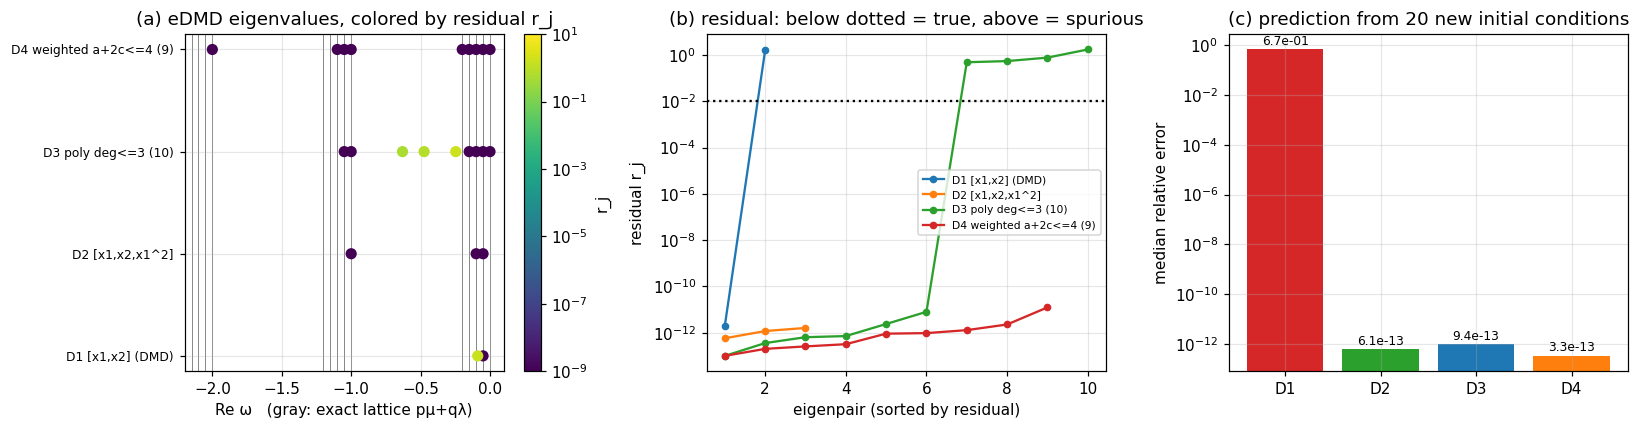

In [6]:
# 1-3. 그림 11 재현 — 고유값(잔차 색), 잔차 정렬, 새 초기조건 예측 --------------------------------------------
import matplotlib as mpl
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
norm = mpl.colors.LogNorm(1e-9, 1e1)
for i, (name, res) in enumerate(R1.items()):
    sc = ax[0].scatter(res["omega"].real, np.full(len(res["omega"]), i), c=np.maximum(res["r"], 1e-9), cmap="viridis", norm=norm, s=40, zorder=3)
    ax[1].semilogy(np.arange(1, len(res["r"])+1), np.sort(np.maximum(res["r"], 1e-13)), "o-", ms=4, label=name)
for l in lattice: ax[0].axvline(l, color="gray", lw=0.6, zorder=1)
ax[0].set_yticks(range(4)); ax[0].set_yticklabels(list(R1.keys()), fontsize=8); ax[0].set_xlabel("Re ω   (gray: exact lattice pμ+qλ)"); ax[0].set_title("(a) eDMD eigenvalues, colored by residual r_j"); ax[0].set_xlim(-2.2, 0.1)
plt.colorbar(sc, ax=ax[0], label="r_j")
ax[1].axhline(1e-2, color="k", ls=":"); ax[1].set_xlabel("eigenpair (sorted by residual)"); ax[1].set_ylabel("residual r_j"); ax[1].set_title("(b) residual: below dotted = true, above = spurious"); ax[1].legend(fontsize=7)
ax[2].bar(range(4), [v["pred_err"] for v in R1.values()], color=["C3", "C2", "C0", "C1"]); ax[2].set_yscale("log"); ax[2].set_xticks(range(4)); ax[2].set_xticklabels(["D1", "D2", "D3", "D4"])
for i, v in enumerate(R1.values()): ax[2].text(i, v["pred_err"]*1.5, f"{v['pred_err']:.1e}", ha="center", fontsize=8)
ax[2].set_ylabel("median relative error"); ax[2].set_title("(c) prediction from 20 new initial conditions")
plt.tight_layout(); plt.show()


D4 에서 찾은 φλ 의 계수 (ω = -1.0000):


,coefficient
x1^2,-1.111
x2,1


(7.84): φλ = x2 - b x1^2,  b = 1.1111  →  x1^2 계수 -1.1111  | 데이터: -1.1111


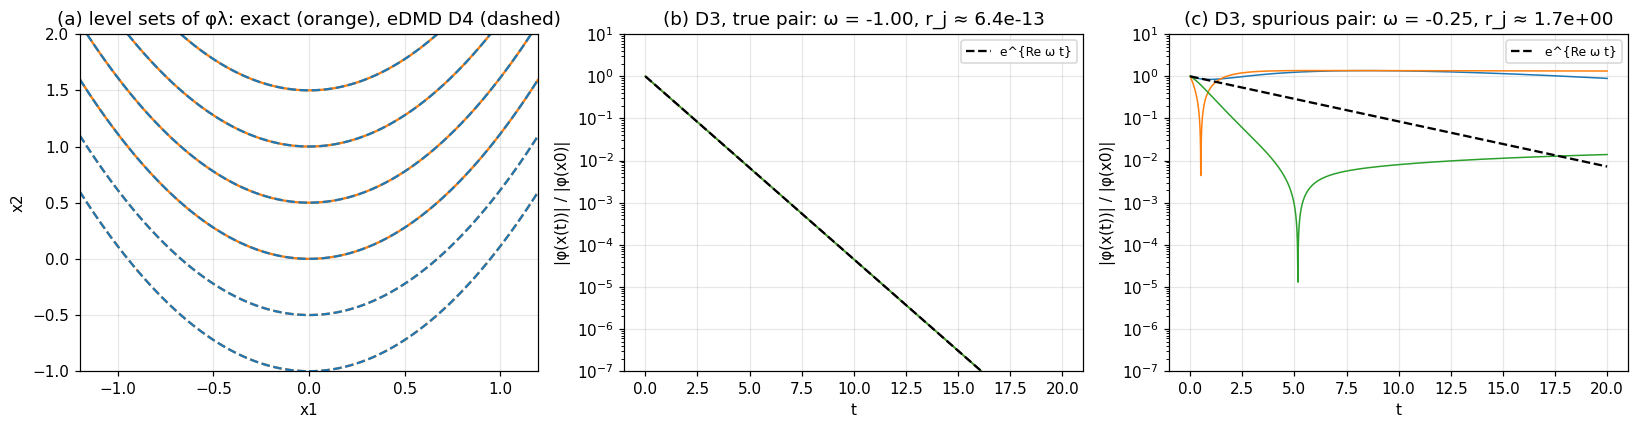

In [7]:
# 1-4. D4 의 φλ 계수 vs (7.84),  그림 12 — 등고선과 궤적 위 선형성 (참 vs 가짜) ---------------------------------
res4 = R1["D4 weighted a+2c<=4 (9)"]; exps4 = res4["exps"]; names4 = [mono_name(e, ['x1', 'x2']) for e in exps4]
j_lam = int(np.argmin(np.abs(res4["omega"] - lam_)))
xi = res4["Xi"][:, j_lam].real; xi = xi/xi[exps4.index((0, 1))]            # x2 계수 = 1 로 정규화
coef = pd.Series(np.round(xi, 4), index=names4); print("D4 에서 찾은 φλ 의 계수 (ω = %.4f):" % res4["omega"][j_lam].real); display(coef[np.abs(coef) > 1e-6].to_frame("coefficient"))
print(f"(7.84): φλ = x2 - b x1^2,  b = {b:.4f}  →  x1^2 계수 {-b:.4f}  | 데이터: {xi[exps4.index((2,0))]:.4f}")

res3 = R1["D3 poly deg<=3 (10)"]; exps3 = res3["exps"]
j_true = int(np.argmin(np.abs(res3["omega"] - lam_)))                       # D3 의 참 고유쌍 (ω=-1)
j_spur = int(np.argmax(res3["r"]))                                          # D3 의 가짜 고유쌍 (잔차 최대)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
g1, g2 = np.meshgrid(np.linspace(-1.2, 1.2, 121), np.linspace(-1, 2, 121)); G = np.column_stack([g1.ravel(), g2.ravel()])
phi_data = (lift_monomials(G, exps4) @ xi).reshape(g1.shape); phi_exact = g2 - b*g1**2
ax[0].contour(g1, g2, phi_exact, levels=np.linspace(-1, 2, 7), colors="C1"); ax[0].contour(g1, g2, phi_data, levels=np.linspace(-1, 2, 7), colors="C0", linestyles="--")
ax[0].set_xlabel("x1"); ax[0].set_ylabel("x2"); ax[0].set_title("(a) level sets of φλ: exact (orange), eDMD D4 (dashed)")
for a, j, lab in [(ax[1], j_true, "true pair"), (ax[2], j_spur, "spurious pair")]:
    om = res3["omega"][j]; xi3 = res3["Xi"][:, j]
    for s in S_te[:3]:
        phi_t = np.abs(lift_monomials(s, exps3) @ xi3); a.semilogy(t_te, phi_t/phi_t[0], "-", lw=1)
    a.semilogy(t_te, np.exp(om.real*t_te), "k--", label="e^{Re ω t}")
    a.set_title(f"({'b' if j==j_true else 'c'}) D3, {lab}: ω = {om.real:.2f}, r_j ≈ {res3['r'][j]:.1e}"); a.set_xlabel("t"); a.set_ylabel("|φ(x(t))| / |φ(x0)|"); a.legend(fontsize=8); a.set_ylim(1e-7, 10)
plt.tight_layout(); plt.show()


**문제 1 해석.**
* **D1(DMD)**: $x_2$의 변화에 필요한 $x_1^2$이 사전에 없어 고유값 하나가 틀리고(이 데이터에서 $-0.09$, 노트의 데이터에서는 $-0.113$ — 초기조건 분포에 따라 달라지는 투영값; 참은 $-1$) 예측이 실패한다(오차 $O(1)$). 사전 밖으로 새는 화살표를 잘라 버린 셈(§1.8 그림 7a).
* **D2**: 세션 1의 닫힌 묶음 → 고유값 $\mu,\lambda,2\mu$ 전부 정확, 잔차 $<10^{-8}$, 예측 오차 $10^{-10}$대 — 사전이 불변 부분공간을 펴면 eDMD = Koopman.
* **D3**: 함수는 가장 많지만 $x_2^3$ 같은 항의 변화율이 4차항을 요구해 닫히지 않음 → 참 6개 + 가짜 4개(잔차 $0.1$–$1$). D2를 포함하므로 상태 예측은 정확 — **예측이 맞는다고 고유값이 다 맞는 것은 아니다.** 그림 12(b)(c): 참 고유쌍은 $|\varphi(x(t))|$가 $e^{\omega t}$를 정확히 따르고 가짜는 따르지 않는다.
* **D4**: $x_2$를 2차로 세는 가중 차수로 고르면 정확히 닫혀 고유값 9개가 모두 격자 $p\mu+q\lambda$ 위. 찾은 $\varphi_\lambda$의 계수 $(x_2:1,\ x_1^2:-1.111)$이 (7.84)와 일치하고 등고선이 해석해와 겹친다(그림 12a).
* 검증 세 가지 — 잔차·궤적 위 선형성·새 초기조건 예측 — 가 모두 필요한 이유가 D3이다: 예측(➂)만 보면 D3은 합격이지만 잔차(➀)와 선형성(➁)이 가짜 4개를 가려낸다.


## 2. 배포 풀이 `w06_solution_bugs.m` 오류 찾기

**문제.** 배포 풀이(MATLAB, 6개 미니문제)에서 결과를 틀리게 만드는 오류를 찾아 (i) 어느 줄이 교재의 어느 식을 어겼는지, (ii) 올바른 코드, (iii) 수정 전후 수치를 기록한다. 데이터는 (7.82) 계라 닫힌 해 (7.85)·고유함수 (7.84)로 검산이 쉽다.

**방법.** 2-1에서 원문을 줄 번호와 함께 출력하고 각 문제의 '검증' 줄과 대조한다. 2-2~2-7은 같은 계산을 Python으로 옮겨 **오류 그대로(before)**와 **수정본(after)**을 나란히 실행한다(배포 함수 `lift`, `edmd`, `koopman_residual`은 0.10의 도구로 대체). 찾은 오류 6건:

| # | 줄 | 원래 코드 | 위반한 식·개념 | 수정 코드 |
|---|---|---|---|---|
| 1 | L18 | `K = [mu 0 0; 0 lam lam; 0 0 2*mu]` | (7.83): $\dot x_2=\lambda x_2-\lambda x_1^2$이므로 (2,3) 성분은 $-\lambda$ | `K = [mu 0 0; 0 lam -lam; 0 0 2*mu]` |
| 2 | L26 | `b = lam/(lam + 2*mu)` | (7.84) $b=\lambda/(\lambda-2\mu)$ (손계산 예 2의 유도) — 부호가 틀리면 $\varphi_\lambda$에 $e^{2\mu t}$ 성분이 남아 순수 지수함수가 아님 | `b = lam/(lam - 2*mu)` |
| 3 | L35 | `A = TX \ TXp` (전치 없음) | (7.98) $A_Y=Y'Y^\dagger$: 행 = 스냅샷인 `TX`로 풀면 $\Theta(X)A\approx\Theta(X')$, 즉 $y_{k+1}^T=y_k^TA$ → $y_{k+1}=Ay_k$로 쓰려면 **전치** 필요. 고유값은 전치해도 같아 ω만 보면 못 잡음 | `A = (TX \ TXp).'` |
| 4 | L46 | `Xi = W` (우고유벡터) | (7.103): 고유함수 계수는 $A_Y$의 **좌고유벡터**($A_Y^T$의 우고유벡터) — 우고유벡터는 모드 | `[Xi, ~] = eig(A.')` (λ 순서를 맞춤) |
| 5 | L63–64 | `... .* Xd(:,1)`, `... .* Xd(:,2)` | (7.104) $\Gamma=[\nabla\theta_j\cdot\dot x]$: $\dot x$ 자리에 $x$를 곱함 → $\nabla\theta\cdot x$는 보존량의 식이 아님 | `.* dXd(:,1)`, `.* dXd(:,2)` |
| 6 | L73 | `Kd = [0.9 0 0; 0 0.5 1; 0 0 0.9]` | 손계산 예 4: $x_1'^2=(0.9x_1)^2=0.81x_1^2$ — (3,3) 성분은 $0.9^2$ (고유값 격자 $\lambda_1^2$) | `Kd(3,3) = 0.81` |


In [8]:
# 2-1. 배포 풀이 원문 (줄 번호) -------------------------------------------------------------------
BUGS_M = Path.cwd() / "w06_solution_bugs.m"
if BUGS_M.exists():
    for i, line in enumerate(BUGS_M.read_text(encoding="utf-8", errors="replace").splitlines(), 1): print(f"{i:3d}| {line}")
else:
    print("[안내] w06_solution_bugs.m 이 노트북 폴더에 없습니다 — 아래 셀들은 파일 없이도 (Python 재현으로) 실행됩니다.")


  1| % w06_solution_bugs.m — [배포 풀이] 6주차 Koopman·eDMD 미니문제 풀이 (MATLAB/Octave, 툴박스 불필요) — ※ 의도적 오류가 여러 곳(5곳 이상) 포함 ※
  2| % 과제 2(오류 찾기): 결과를 틀리게 만드는 오류를 1건 이상 찾아 (i) 어느 줄이 교재의 어느 식을 어겼는지 (ii) 올바른 코드
  3| % (iii) 수정 전후 수치를 연구노트에 기록하라. 힌트: 각 문제의 '검증' 줄이 참값과 맞는지 먼저 확인할 것.
  4| % 데이터: 교재 (7.82) 계 (μ = −0.05, λ = −1) — 닫힌 해 (7.85) 와 고유함수 (7.84) 를 알고 있으므로 검산이 쉽다.
  5| % 필요 파일: lift.m, monomial_exps.m, edmd.m, koopman_residual.m (같은 폴더).  Python 판(w06_solution_bugs.py)과 같은 오류를 담고 있다.
  6| clear; close all; clc; rng(0);
  7| mu = -0.05; lam = -1; dt = 0.01;
  8| b_true = lam / (lam - 2*mu);                                                  % (7.84) 의 b = 1.1111
  9| sol82 = @(x0, t) [x0(1) * exp(mu*t); (x0(2) - b_true*x0(1)^2) * exp(lam*t) + b_true*x0(1)^2 * exp(2*mu*t)];   % (7.85)
 10| t = 0:dt:12;
 11| X = []; Xp = [];
 12| for i = 1:40
 13|     Z = sol82(3 * rand(2, 1) - 1.5, t);
 14|     X = [X; Z(:, 1:end-1).']; Xp = [Xp; Z(:, 2:end).'];                        % 행 = 스냅샷
 15| end
 16| 
 17|

In [9]:
# 2-2. 오류 1 — P1: (7.83) 행렬 K 의 부호 (L18) ------------------------------------------------------------
from scipy.linalg import expm
x0b = np.array([1.5, 3.5]); tb = np.arange(0, 12 + 1e-9, 0.01); Zb = traj82(x0b, tb)          # (7.85) 닫힌 해
for tag, K in [("before (L18 버그)", np.array([[mu, 0, 0], [0, lam_, lam_], [0, 0, 2*mu]])), ("after  (수정)", np.array([[mu, 0, 0], [0, lam_, -lam_], [0, 0, 2*mu]]))]:
    y0 = np.array([x0b[0], x0b[1], x0b[0]**2]); Y = np.array([expm(K*tk) @ y0 for tk in tb])
    print(f"[P1] {tag}: 선형계 (7.83) 과 비선형 해 (7.85) 의 최대 차이 = {np.abs(Y[:, :2] - Zb).max():.1e}")
print("→ (2,3) 성분이 +λ 이면 ẏ2 = λ(x2 + x1²) 가 되어 다른 계. 수정하면 반올림 수준 차이.")


[P1] before (L18 버그): 선형계 (7.83) 과 비선형 해 (7.85) 의 최대 차이 = 3.5e+00
[P1] after  (수정): 선형계 (7.83) 과 비선형 해 (7.85) 의 최대 차이 = 1.2e-14
→ (2,3) 성분이 +λ 이면 ẏ2 = λ(x2 + x1²) 가 되어 다른 계. 수정하면 반올림 수준 차이.


In [10]:
# 2-3. 오류 2 — P2: (7.84) 의 b 부호 (L26) ---------------------------------------------------------------------
for tag, bb in [("before (L26 버그)", lam_/(lam_ + 2*mu)), ("after  (수정)", lam_/(lam_ - 2*mu))]:
    phi = Zb[:, 1] - bb*Zb[:, 0]**2; m_ = tb <= 5; slope = np.polyfit(tb[m_], np.log(np.abs(phi[m_])), 1)[0]
    print(f"[P2] {tag}: b = {bb:.4f},  log|φλ(x(t))| 의 기울기 = {slope:.4f}  (참값 λ = {lam_})")
print("→ b 가 틀리면 φ 에 e^{2μt} 성분이 남아 기울기가 λ 와 2μ 사이의 값이 되고 직선도 아니다. 손계산 예 2 의 유도: λ + 2μb = λb → b = λ/(λ−2μ).")


[P2] before (L26 버그): b = 0.9091,  log|φλ(x(t))| 의 기울기 = -0.3068  (참값 λ = -1.0)
[P2] after  (수정): b = 1.1111,  log|φλ(x(t))| 의 기울기 = -1.0000  (참값 λ = -1.0)
→ b 가 틀리면 φ 에 e^{2μt} 성분이 남아 기울기가 λ 와 2μ 사이의 값이 되고 직선도 아니다. 손계산 예 2 의 유도: λ + 2μb = λb → b = λ/(λ−2μ).


In [11]:
# 2-4. 오류 3 — P3: (7.98) 회귀의 전치 (L35) -----------------------------------------------------------------------
exps2 = [(1, 0), (0, 1), (2, 0)]; TX2, TXp2 = lift_monomials(X1, exps2), lift_monomials(X1p, exps2)
Zt = traj82(np.array([1.2, -0.8]), t_te)
for tag, A in [("before (L35 버그: 전치 없음)", np.linalg.lstsq(TX2, TXp2, rcond=None)[0]), ("after  (수정: 전치)", np.linalg.lstsq(TX2, TXp2, rcond=None)[0].T)]:
    res1 = np.linalg.norm(TXp2.T - A @ TX2.T)/np.linalg.norm(TXp2.T)
    y = lift_monomials(Zt[:1], exps2)[0]; pred = [Zt[0]]
    for k in range(1, len(t_te)): y = A @ y; pred.append(y[:2])
    pred = np.array(pred); om = np.sort(np.log(np.linalg.eigvals(A).astype(complex)).real/dt1)
    print(f"[P3] {tag:26s}: 1스텝 상대잔차 {res1:.1e}, 20초 예측 상대오차 {np.linalg.norm(pred - Zt)/np.linalg.norm(Zt):.1e}, ω = {np.round(om, 4)}")
print("→ 고유값(ω)은 전치해도 같으므로 ω 만 보면 못 잡는다 — 잔차·예측으로 잡아야 한다 (파일의 '검증' 줄이 말하는 그대로).")


[P3] before (L35 버그: 전치 없음)    : 1스텝 상대잔차 8.8e-03, 20초 예측 상대오차 6.6e-01, ω = [-1.   -0.1  -0.05]
[P3] after  (수정: 전치)           : 1스텝 상대잔차 1.0e-15, 20초 예측 상대오차 6.6e-13, ω = [-1.   -0.1  -0.05]
→ 고유값(ω)은 전치해도 같으므로 ω 만 보면 못 잡는다 — 잔차·예측으로 잡아야 한다 (파일의 '검증' 줄이 말하는 그대로).


In [12]:
# 2-5. 오류 4 — P4: 고유함수 계수에 우고유벡터 사용 (L46) ---------------------------------------------------------
A4 = np.linalg.lstsq(TX2, TXp2, rcond=None)[0].T; lam4, W4 = np.linalg.eig(A4)
def resid(TX, TXp, Xi, lam):
    Phi, PhiP = TX @ Xi, TXp @ Xi; return np.linalg.norm(PhiP - Phi*lam, axis=0)/(np.abs(lam - 1)*np.linalg.norm(Phi, axis=0))
lamT, XiT = np.linalg.eig(A4.T); XiL = XiT[:, [int(np.argmin(np.abs(lamT - l))) for l in lam4]]      # 좌고유벡터, λ 순서 맞춤
for tag, Xi in [("before (L46 버그: 우고유벡터)", W4), ("after  (수정: 좌고유벡터)", XiL)]:
    print(f"[P4] {tag:28s}: ω = {np.round(np.log(lam4.astype(complex)).real/dt1, 4)},  잔차 r_j = {np.array2string(resid(TX2, TXp2, Xi, lam4), precision=1)}")
print("→ 우고유벡터(모드)로 φ = Θ ξ 를 만들면 고유함수가 아니라 잔차 O(1); 좌고유벡터면 세 쌍 모두 1e-9 이하 (7.103).")


[P4] before (L46 버그: 우고유벡터)      : ω = [-0.05 -1.   -0.1 ],  잔차 r_j = [0.  0.9 1.5]
[P4] after  (수정: 좌고유벡터)          : ω = [-0.05 -1.   -0.1 ],  잔차 r_j = [0. 0. 0.]
→ 우고유벡터(모드)로 φ = Θ ξ 를 만들면 고유함수가 아니라 잔차 O(1); 좌고유벡터면 세 쌍 모두 1e-9 이하 (7.103).


In [13]:
# 2-6. 오류 5 — P5: Γ 에 ẋ 대신 x 를 곱함 (L63–64) — 비감쇠 Duffing 의 보존량 ------------------------------------------
from scipy.integrate import solve_ivp
duff = lambda tt, s_: [s_[1], s_[0] - s_[0]**3]
Xd, dXd = [], []
for ic in [(-1.5, 0), (0.3, 0.2), (1.3, 0.6), (0, 1.3), (-0.2, -1.0)]:
    sol = solve_ivp(duff, (0, 15), ic, t_eval=np.arange(0, 15 + 1e-9, 0.02), rtol=1e-10, atol=1e-12); Zd = sol.y.T
    Xd.append(Zd); dXd.append(np.column_stack([Zd[:, 1], Zd[:, 0] - Zd[:, 0]**3]))
Xd, dXd = np.vstack(Xd), np.vstack(dXd)
exd = monomial_exps(2, 4, include_const=False); names_d = [mono_name(e, ['x1', 'x2']) for e in exd]
def gamma_matrix(mult):                               # Γ_j = ∂θ_j/∂x1 · mult[:,0] + ∂θ_j/∂x2 · mult[:,1]
    G = np.zeros((len(Xd), len(exd)))
    for j, (a, c) in enumerate(exd):
        if a > 0: G[:, j] += a*Xd[:, 0]**(a-1)*Xd[:, 1]**c*mult[:, 0]
        if c > 0: G[:, j] += c*Xd[:, 0]**a*Xd[:, 1]**(c-1)*mult[:, 1]
    return G
for tag, mult in [("before (L63-64 버그: ∇θ·x)", Xd), ("after  (수정: ∇θ·ẋ)", dXd)]:
    G = gamma_matrix(mult); _, sv, Vt = np.linalg.svd(-G, full_matrices=False); xi = Vt[-1]; xi = xi/np.linalg.norm(xi)
    if xi[names_d.index("x2^2")] < 0: xi = -xi
    print(f"[P5] {tag:26s}: σ_min/σ_1 = {sv[-1]/sv[0]:.1e},  영벡터 계수: x1² {xi[names_d.index('x1^2')]:+.3f}, x2² {xi[names_d.index('x2^2')]:+.3f}, x1⁴ {xi[names_d.index('x1^4')]:+.3f}  [(7.106): -0.667, +0.667, +0.333]")
print("→ ∇θ·x 는 Euler 항등식(차수 × θ)이라 Γ 가 Θ 의 열 척도 변환이 되어 영공간이 없고(σ_min/σ_1 ~ 1e-2, 0 아님), 영벡터 계수도 엉뚱하다. ∇θ·ẋ 라야 λ=0 고유함수 = 4/3 H 가 영벡터(σ_min/σ_1 ~ 1e-16)로 나온다.")


[P5] before (L63-64 버그: ∇θ·x)  : σ_min/σ_1 = 2.2e-02,  영벡터 계수: x1² -0.301, x2² +0.100, x1⁴ +0.053  [(7.106): -0.667, +0.667, +0.333]
[P5] after  (수정: ∇θ·ẋ)         : σ_min/σ_1 = 5.8e-17,  영벡터 계수: x1² -0.667, x2² +0.667, x1⁴ +0.333  [(7.106): -0.667, +0.667, +0.333]
→ ∇θ·x 는 Euler 항등식(차수 × θ)이라 Γ 가 Θ 의 열 척도 변환이 되어 영공간이 없고(σ_min/σ_1 ~ 1e-2, 0 아님), 영벡터 계수도 엉뚱하다. ∇θ·ẋ 라야 λ=0 고유함수 = 4/3 H 가 영벡터(σ_min/σ_1 ~ 1e-16)로 나온다.


In [14]:
# 2-7. 오류 6 — P6: 손계산 예 4 의 K (3,3) 성분 (L73) ------------------------------------------------------------------
rng6 = np.random.default_rng(0); P6 = rng6.uniform(-1, 1, (200, 2)); Pn6 = np.column_stack([0.9*P6[:, 0], 0.5*P6[:, 1] + P6[:, 0]**2])
Ad = np.linalg.lstsq(lift_monomials(P6, exps2), lift_monomials(Pn6, exps2), rcond=None)[0].T
for tag, Kd_ in [("before (L73 버그)", np.array([[0.9, 0, 0], [0, 0.5, 1], [0, 0, 0.9]])), ("after  (수정)", np.array([[0.9, 0, 0], [0, 0.5, 1], [0, 0, 0.81]]))]:
    print(f"[P6] {tag}: 손계산 K 의 고유값 = {np.round(np.sort(np.linalg.eigvals(Kd_)), 4)},  데이터 eDMD 행렬과의 최대 차이 = {np.abs(Ad - Kd_).max():.1e}")
print("→ x1'^2 = (0.9 x1)^2 = 0.81 x1^2 — 고유값 0.81 = 0.9^2 는 곱 고유함수의 격자 (7.71)–(7.72). 데이터 행렬은 이것을 정확히 복원한다.")


[P6] before (L73 버그): 손계산 K 의 고유값 = [0.5 0.9 0.9],  데이터 eDMD 행렬과의 최대 차이 = 9.0e-02
[P6] after  (수정): 손계산 K 의 고유값 = [0.5  0.81 0.9 ],  데이터 eDMD 행렬과의 최대 차이 = 4.4e-16
→ x1'^2 = (0.9 x1)^2 = 0.81 x1^2 — 고유값 0.81 = 0.9^2 는 곱 고유함수의 격자 (7.71)–(7.72). 데이터 행렬은 이것을 정확히 복원한다.


**문제 2 정리.** 여섯 오류는 모두 6주차의 식 한 줄씩에 대응한다: (7.83)의 부호(1), (7.84)의 $b$(2), (7.98)의 전치 — $y_{k+1}=A_Yy_k$ 규약(3), (7.103) 좌고유벡터(4), (7.104)의 $\Gamma=\nabla\theta\cdot\dot x$(5), 격자 고유값 $\lambda_1^2$(6). 파일의 '검증' 줄이 각각의 증상(차이 $O(1)$ / 기울기 ≠ λ / 잔차 $O(1)$인데 ω는 정상 / 세 쌍 모두 잔차 큼 / 영공간 없음 / 고유값 0.9 중복)을 가리킨다. 특히 3번은 **고유값만으로는 잡히지 않는** 오류라 잔차·예측 검증(§2.3)이 왜 필요한지를 보여 준다. Python 재현은 난수가 MATLAB과 달라 수치는 다르지만 수정 전후의 정성적 차이(반올림 수준 ↔ $O(1)$)는 같다.


## 3. 개인 탐구문제 — 정전 구동 CNT 공진기 과도응답의 eDMD

### 3-0. 데이터와 목표
W02·W04에서 쓴 연구 모델(정전 구동 CNT 캔틸레버, `main_0819.jl`의 무차원 운동방정식)을 **시간 영역에서 직접 적분**해 과도응답 데이터를 만든다:
$$(1+\alpha_Ix^2)\ddot x+c\dot x+\omega_1^2x+\alpha_Gx^3+\alpha_Ix\dot x^2=d_2\gamma_2\frac{V(t)^2}{(y_{PI}-x)^{0.68}},\qquad V=V_{DC}+V_{AC}\cos\Omega_dt,\ \Omega_d=\Omega\sqrt{\omega_1^2}.$$
($Q=20,\ \omega_1^2=12.362,\ \alpha_G=0.984,\ \alpha_I=0.112,\ d_2\gamma_2=0.2884,\ y_{PI}=0.5,\ V_{DC}=1,\ V_{AC}=0.19$ — W02·W04의 HBM 데이터와 같은 계.)

**이 계의 Koopman 관점에서의 특징 세 가지** (사전 설계와 한계의 근거):
1. **주기 가진(비자율계)**: 가진 위상 $\tau=\Omega_dt$를 상태에 넣으면 $(\cos\tau,\sin\tau)$는 정확히 선형(회전)으로 닫힌다. 그래서 관측 벡터를 $(x,\dot x,\cos\tau,\sin\tau)$로 두고, 사전에 $\cos\tau,\sin\tau$와 그 곱을 포함한다.
2. **끌개가 주기궤도**: 안정 주기해 근처에서 Koopman 고유값은 **Floquet 지수** $\ln\mu/T$(mod $i\Omega_d$)와 가진 고조파 $ik\Omega_d$의 격자 — 연구에서 Hill–Floquet으로 계산해 둔 승수 $\mu$(`*_matlab_floquet_stability.csv`)와 직접 대조할 수 있다.
3. **비다항 전기력 + 여러 끌개**: $1/(y_{PI}-x)^{0.68}$은 다항식 사전으로 닫히지 않고(로지스틱 사상처럼 무한 사슬, §1.8), $\Omega$에 따라 main 주기해·isola 주기해·풀인(발산)이 공존한다(§2.5 여러 끌개).

**설계.**
* **경우 A — 끌개 하나** ($\Omega=1.0$, $\Omega_d=3.516=\omega_1$, main 가지 진폭 0.23): 훈련 초기조건 30개·시험 10개, 40주기, $\Delta t=T/32$. 사전 4가지로 eDMD → 고유값·$r_j$·새 초기조건 예측·가짜 가려내기·닫히지 않는 항 추정.
* **경우 B — 끌개 여럿** ($\Omega=0.9$: main 진폭 0.155 + isola 진폭 0.477 + 풀인 공존): isola 궤도 근처 초기조건(HBM 해에서 시작)과 원점 근처 초기조건을 섞어 학습 → §2.5의 실패를 확인하고, isola 끌림 영역만으로 학습하면 isola의 Floquet 지수가 나오는지 본다.


경우 A: Ω=1.0, Ω_d=3.516, T=1.787, Δt=0.0558, 스텝 1280, |x|max(훈련) = 0.342 (풀인 0.5 미만)


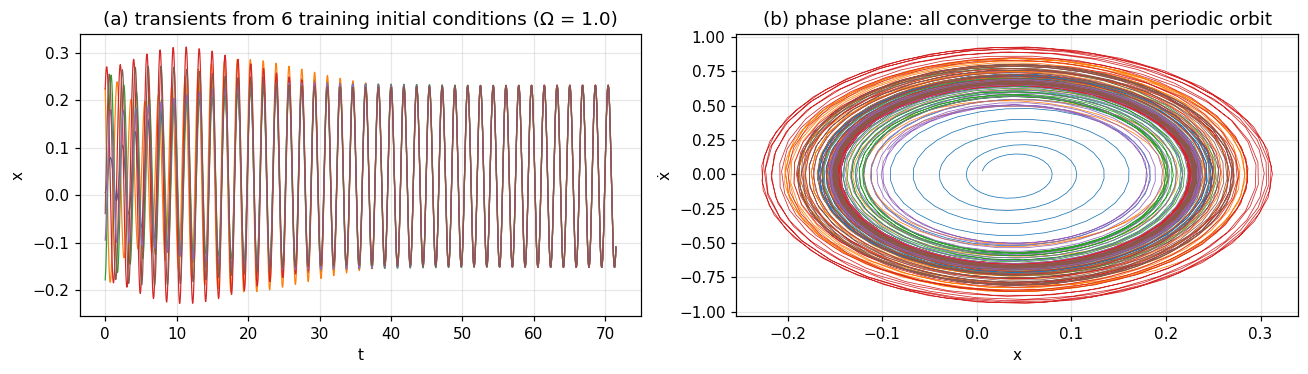

In [15]:
# 3-1. 모델·적분기·데이터 생성 ------------------------------------------------------------------------------
PRM = dict(Q=20.0, w1sq=12.362, aG=0.984, aI=0.112, d2g2=0.028*10.3, m=0.68, yPI=0.5, VDC=1.0, VAC=0.19); PRM["c"] = 3.516/PRM["Q"]
def cnt_rhs(t, X, Od):
    x, v = X[0], X[1]; V = PRM["VDC"] + PRM["VAC"]*np.cos(Od*t); g = np.maximum(PRM["yPI"] - x, 1e-3)
    a = (PRM["d2g2"]*V**2/g**PRM["m"] - PRM["c"]*v - PRM["w1sq"]*x - PRM["aG"]*x**3 - PRM["aI"]*x*v**2)/(1 + PRM["aI"]*x**2)
    return np.array([v, a])
def rk4(X0, Od, dt, n):                     # X0: (2, nIC) — 초기조건 여러 개를 한꺼번에 적분
    X = X0.copy(); out = np.empty((n+1,) + X0.shape); out[0] = X; t = 0.0
    for k in range(n):
        k1 = cnt_rhs(t, X, Od); k2 = cnt_rhs(t+dt/2, X+dt/2*k1, Od); k3 = cnt_rhs(t+dt/2, X+dt/2*k2, Od); k4 = cnt_rhs(t+dt, X+dt*k3, Od)
        X = X + dt/6*(k1 + 2*k2 + 2*k3 + k4); t += dt; out[k+1] = X
    return out

def make_data(Om, X0_tr, X0_te, nper=40, NPP=32):
    Od = Om*np.sqrt(PRM["w1sq"]); T = 2*np.pi/Od; dt = T/NPP; n = NPP*nper
    S_tr, S_te = rk4(X0_tr, Od, dt, n), rk4(X0_te, Od, dt, n); t = np.arange(n+1)*dt; tau = Od*t
    def obs(S):                              # (n+1, nIC, 4): x, v, cosτ, sinτ
        c = np.cos(tau)[:, None]*np.ones(S.shape[2]); s = np.sin(tau)[:, None]*np.ones(S.shape[2])
        return np.stack([S[:, 0], S[:, 1], c, s], -1)
    return dict(Om=Om, Od=Od, T=T, dt=dt, t=t, S_tr=S_tr, S_te=S_te, Z_tr=obs(S_tr), Z_te=obs(S_te))

rngA = np.random.default_rng(1)
icA = lambda m: np.stack([rngA.uniform(-0.25, 0.25, m), rngA.uniform(-0.8, 0.8, m)])
DA = make_data(1.0, icA(30), icA(10))
print(f"경우 A: Ω={DA['Om']}, Ω_d={DA['Od']:.3f}, T={DA['T']:.3f}, Δt={DA['dt']:.4f}, 스텝 {len(DA['t'])-1}, |x|max(훈련) = {np.abs(DA['S_tr'][:,0]).max():.3f} (풀인 0.5 미만)")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for i in range(6): ax[0].plot(DA["t"], DA["S_tr"][:, 0, i], lw=0.8)
ax[0].set_xlabel("t"); ax[0].set_ylabel("x"); ax[0].set_title("(a) transients from 6 training initial conditions (Ω = 1.0)")
for i in range(6): ax[1].plot(DA["S_tr"][:, 0, i], DA["S_tr"][:, 1, i], lw=0.5)
ax[1].set_xlabel("x"); ax[1].set_ylabel("ẋ"); ax[1].set_title("(b) phase plane: all converge to the main periodic orbit")
plt.tight_layout(); plt.show()


In [16]:
# 3-2. 사전 네 가지와 eDMD ---------------------------------------------------------------------------------
# 사전 항 (a, b, k, f): x^a ẋ^b × {1 (k=0), cos kτ (f='c'), sin kτ (f='s')} — 가진 고조파 k 와의 곱까지 허용
def lift_cnt(Z, dic):
    x, v, c, s = Z[..., 0], Z[..., 1], Z[..., 2], Z[..., 3]; tau = np.arctan2(s, c); cols, names = [], []
    for a, b_, k, fo in dic:
        h = 1.0 if k == 0 else (np.cos(k*tau) if fo == "c" else np.sin(k*tau))
        cols.append(x**a * v**b_ * h)
        nm = (f"x^{a}" if a else "") + (f"v^{b_}" if b_ else "") + ("" if k == 0 else f"·{fo}{k}τ"); names.append(nm if nm else "1")
    return np.stack(cols, -1), names
mono2 = lambda deg: [(a, b_) for a in range(deg+1) for b_ in range(deg+1) if 0 < a+b_ <= deg]
def make_dict(deg_poly=3, K=1, deg_h=0):
    # 상수·x·ẋ·cosτ·sinτ + (x,ẋ) 단항식 차수≤deg_poly + 가진 고조파 k≤K (단독 및 × 차수≤deg_h 단항식)
    d = [(0, 0, 0, ""), (1, 0, 0, ""), (0, 1, 0, ""), (0, 0, 1, "c"), (0, 0, 1, "s")]
    d += [(a, b_, 0, "") for a, b_ in mono2(deg_poly) if a+b_ >= 2]
    d += [(0, 0, k, fo) for k in range(2, K+1) for fo in "cs"]
    d += [(a, b_, k, fo) for a, b_ in mono2(deg_h) for k in range(1, K+1) for fo in "cs"]
    return d
DICTS_C = {"D1 DMD+forcing (5)":            make_dict(deg_poly=1, K=1, deg_h=0),
           "D2 +poly deg<=3 (12)":          make_dict(deg_poly=3, K=1, deg_h=0),
           "D3 +cosτ,sinτ × deg<=2 (22)":   make_dict(deg_poly=3, K=1, deg_h=2),
           "D4 +harmonics k<=3 × deg<=2 (46)": make_dict(deg_poly=3, K=3, deg_h=2)}
for k, v in DICTS_C.items(): print(f"{k:34s} p = {len(v)}")

def run_edmd_cnt(D, dic):
    Z, Zp = D["Z_tr"][:-1].reshape(-1, 4), D["Z_tr"][1:].reshape(-1, 4)
    TX, names = lift_cnt(Z, dic); TXp, _ = lift_cnt(Zp, dic)
    res = edmd(TX, TXp, D["dt"]); res["names"] = names; res["dic"] = dic
    y0 = lift_cnt(D["Z_te"][0], dic)[0].T; pred = predict(res["A"], y0, len(D["t"])-1)
    ix = names.index("x^1"); xp, xt = pred[:, ix, :], D["S_te"][:, 0, :]
    res["pred_err_each"] = np.linalg.norm(xp - xt, axis=0)/np.linalg.norm(xt, axis=0)
    res["pred_err"] = float(np.median(res["pred_err_each"])); res["pred_x"] = xp
    return res
RA = {k: run_edmd_cnt(DA, v) for k, v in DICTS_C.items()}

# Floquet 대조: 연구의 Hill–Floquet 승수 μ (main 가지, Ω≈1.0) → ω = ln|μ|/T ± i(arg μ/T + kΩ_d)
flA = pd.read_csv(DATA_DIR / "Q_20_DC_1_AC_0.19_Ω_0.7_HBM_coeffs_branch01_matlab_floquet_stability.csv")
rowA = flA.iloc[(flA.Omega - DA["Om"]).abs().argmin()]
fl_re, fl_im = np.log(rowA.mu1_abs)/DA["T"], np.arctan2(rowA.mu1_im, rowA.mu1_re)/DA["T"]
fl_target = fl_re + 1j*(DA["Od"] - fl_im)
print(f"Hill–Floquet (Ω={rowA.Omega:.4f}): μ = {rowA.mu1_re:.4f}{rowA.mu1_im:+.4f}i, |μ| = {rowA.mu1_abs:.4f}  →  ω_F = {fl_re:.4f} ± {fl_im:.4f}i  (mod iΩ_d = {DA['Od']:.3f}i);  이론값 Re = -c/2 = {-PRM['c']/2:.4f}")
print(f"→ eDMD 와 비교할 격자점: {fl_target:.4f}  (k = -1 가지)")
tabA = pd.DataFrame([{"dictionary": k, "p": len(v["names"]), "pred. error (10 new ICs, 40 periods)": v["pred_err"],
                      "r_j<1e-2": int(np.sum(v["r"] < 1e-2)), "r_j<1e-8 (exact)": int(np.sum(v["r"] < 1e-8)),
                      "ω closest to Floquet": f"{v['omega'][np.argmin(np.abs(v['omega'] - fl_target))]:.4f}",
                      "its r_j": f"{v['r'][np.argmin(np.abs(v['omega'] - fl_target))]:.1e}"} for k, v in RA.items()]).set_index("dictionary")
display(tabA)


D1 DMD+forcing (5)                 p = 5
D2 +poly deg<=3 (12)               p = 12
D3 +cosτ,sinτ × deg<=2 (22)        p = 22
D4 +harmonics k<=3 × deg<=2 (46)   p = 46
Hill–Floquet (Ω=1.0000): μ = 0.8357+0.1802i, |μ| = 0.8549  →  ω_F = -0.0877 ± 0.1189i  (mod iΩ_d = 3.516i);  이론값 Re = -c/2 = -0.0879
→ eDMD 와 비교할 격자점: -0.0877+3.3971j  (k = -1 가지)


,p,"pred. error (10 new ICs, 40 periods)",r_j<1e-2,r_j<1e-8 (exact),ω closest to Floquet,its r_j
dictionary,,,,,,
D1 DMD+forcing (5),5,0.02238,3,3,-0.0910+3.3975j,2.1e-02
D2 +poly deg<=3 (12),12,0.02611,3,3,-0.0915+3.3937j,1.7e-02
"D3 +cosτ,sinτ × deg<=2 (22)",22,0.02073,7,3,-0.1035+3.3979j,1.1e-02
D4 +harmonics k<=3 × deg<=2 (46),46,0.001627,27,7,-0.0882+3.3968j,2.6e-03


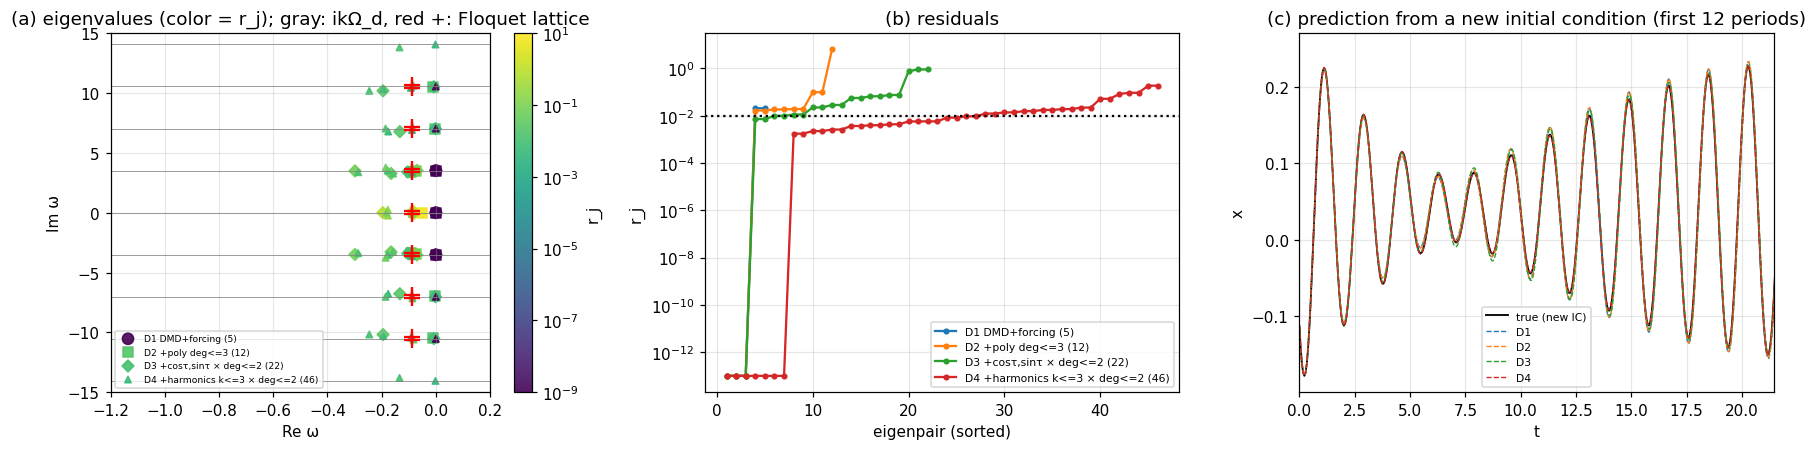

In [17]:
# 3-3. 고유값(잔차 색)·잔차·예측 — 경우 A ------------------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
norm = mpl.colors.LogNorm(1e-9, 1e1)
for i, (k, v) in enumerate(RA.items()):
    sc = ax[0].scatter(v["omega"].real, v["omega"].imag, c=np.maximum(v["r"], 1e-9), cmap="viridis", norm=norm, s=18 + 12*(3-i), marker="osD^"[i], label=k, alpha=0.9)
for kk in range(-4, 5): ax[0].axhline(kk*DA["Od"], color="gray", lw=0.5)
for sgn in (1, -1):
    for kk in range(-3, 4): ax[0].plot(fl_re, sgn*fl_im + kk*DA["Od"], "r+", ms=10, mew=1.5)
ax[0].set_xlim(-1.2, 0.2); ax[0].set_ylim(-15, 15); ax[0].set_xlabel("Re ω"); ax[0].set_ylabel("Im ω"); ax[0].set_title("(a) eigenvalues (color = r_j); gray: ikΩ_d, red +: Floquet lattice"); ax[0].legend(fontsize=6, loc="lower left")
plt.colorbar(sc, ax=ax[0], label="r_j")
for k, v in RA.items(): ax[1].semilogy(np.arange(1, len(v["r"])+1), np.sort(np.maximum(v["r"], 1e-13)), "o-", ms=3, label=k)
ax[1].axhline(1e-2, color="k", ls=":"); ax[1].set_xlabel("eigenpair (sorted)"); ax[1].set_ylabel("r_j"); ax[1].set_title("(b) residuals"); ax[1].legend(fontsize=7)
i0 = 0
ax[2].plot(DA["t"], DA["S_te"][:, 0, i0], "k", lw=1.2, label="true (new IC)")
for k, v in RA.items(): ax[2].plot(DA["t"], v["pred_x"][:, i0], "--", lw=0.9, label=k.split(" ")[0])
ax[2].set_xlim(0, 12*DA["T"]); ax[2].set_xlabel("t"); ax[2].set_ylabel("x"); ax[2].set_title("(c) prediction from a new initial condition (first 12 periods)"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()


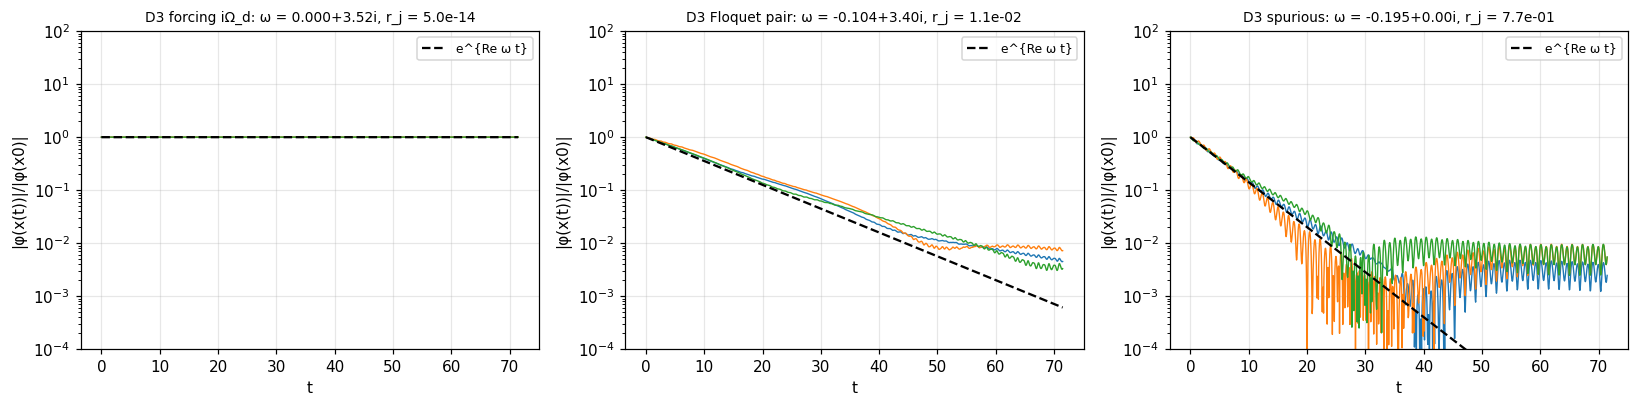

읽는 법: 참 고유쌍이면 |φ(x(t))| 가 e^{Re ω t} 직선(점선)을 따라가고, 가짜면 따르지 않는다. 가진 iΩ_d 쌍은 Re ω = 0 이라 수평선, Floquet 쌍은 -c/2 로 감쇠.


In [18]:
# 3-4. 가짜 고유쌍 가려내기 (그림 12 방식) — D3 의 잔차 작은 쌍 vs 큰 쌍을 시험 궤적 위에서 --------------------------
v3 = RA["D3 +cosτ,sinτ × deg<=2 (22)"]; names3 = v3["names"]
j_fl  = int(np.argmin(np.abs(v3["omega"] - fl_target)))                               # Floquet 에 가장 가까운 쌍
j_forc = int(np.argmin(np.abs(v3["omega"] - 1j*DA["Od"])))                             # 가진 기본파 iΩ_d
cand = np.where(v3["r"] > 1e-1)[0]; j_sp = int(cand[np.argmax(np.abs(v3["omega"][cand].real))]) if len(cand) else int(np.argmax(v3["r"]))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, j, lab in [(ax[0], j_forc, "forcing iΩ_d"), (ax[1], j_fl, "Floquet pair"), (ax[2], j_sp, "spurious")]:
    om = v3["omega"][j]; xi = v3["Xi"][:, j]
    for i in range(3):
        phi = np.abs(lift_cnt(DA["Z_te"][:, i, :], v3["dic"])[0] @ xi); a.semilogy(DA["t"], phi/phi[0], lw=0.9)
    a.semilogy(DA["t"], np.exp(om.real*DA["t"]), "k--", label="e^{Re ω t}")
    a.set_title(f"D3 {lab}: ω = {om.real:.3f}{om.imag:+.2f}i, r_j = {v3['r'][j]:.1e}", fontsize=9); a.set_xlabel("t"); a.set_ylabel("|φ(x(t))|/|φ(x0)|"); a.legend(fontsize=8); a.set_ylim(1e-4, 1e2)
plt.tight_layout(); plt.show()
print("읽는 법: 참 고유쌍이면 |φ(x(t))| 가 e^{Re ω t} 직선(점선)을 따라가고, 가짜면 따르지 않는다. 가진 iΩ_d 쌍은 Re ω = 0 이라 수평선, Floquet 쌍은 -c/2 로 감쇠.")


### 3-5. 닫히지 않는 항 추정 — 잔차 바닥 $10^{-2}$의 정체

D1 → D3까지는 사전을 키워도 Floquet 쌍의 잔차가 $10^{-2}$ 근처에 머문다. §1.8의 "화살표 긋기"로 후보 원인을 나열하면:
1. 전기력 $(y_{PI}-x)^{-0.68}$은 다항식이 아니다 → 무한 급수(로지스틱 사상 (7.90)과 같은 사슬).
2. $V(t)^2=(V_{DC}+V_{AC}\cos\tau)^2$가 곱해지고 주기궤도 $x_p(\tau)$ 자체가 고조파를 가지므로, 주기궤도 근방의 Floquet 고유함수는 $\varphi\approx u(\tau)^T\big(x-x_p(\tau)\big)$ 꼴 — **가진 고조파 $\cos k\tau,\sin k\tau$ ($k\ge2$)와 상태의 곱**이 필요하다.
3. $(1+\alpha_Ix^2)^{-1}$도 유리함수.

아래 셀은 두 가지를 분리해서 본다: (a) 다항 차수만 올렸을 때와 (b) 가진 고조파 수 $K$를 올렸을 때 Floquet 쌍의 잔차·예측 오차가 어떻게 변하는가, 그리고 (c) 데이터 범위에서 $(y_{PI}-x)^{-0.68}$의 다항 근사 오차.


,sweep,value,p,omega,r_Floquet,pred_err
0,poly degree (K=1),1,5,-0.0910+3.3975j,0.0207,0.02238
1,poly degree (K=1),2,8,-0.0909+3.3973j,0.0148,0.02151
2,poly degree (K=1),3,12,-0.0915+3.3937j,0.01666,0.02611
3,poly degree (K=1),5,23,-0.0917+3.3968j,0.01389,0.0255
4,forcing harmonics K (deg_h=2),1,22,-0.1035+3.3979j,0.01126,0.02073
5,forcing harmonics K (deg_h=2),2,34,-0.0883+3.3972j,0.005087,0.00163
6,forcing harmonics K (deg_h=2),3,46,-0.0882+3.3968j,0.002611,0.001627
7,forcing harmonics K (deg_h=2),4,58,-0.0882+3.3967j,0.002535,0.00163


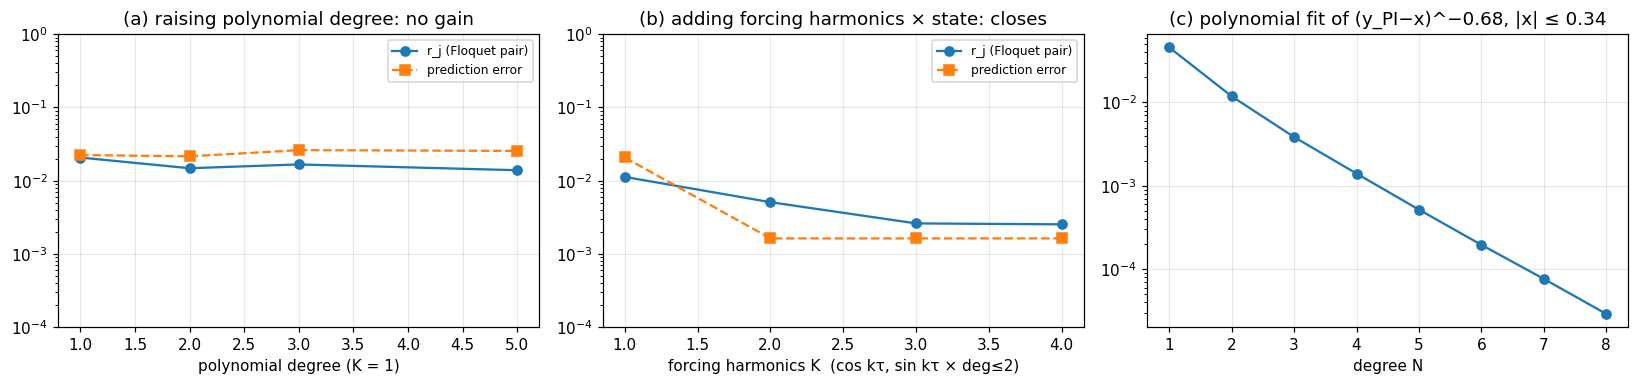

(c) 다항 근사 오차: [0.0457 0.0119 0.0038 0.0014 0.0005 0.0002 0.0001 0.    ]  → 전기력의 급수는 3차에서 이미 0.4 %, 잔차 바닥의 주원인이 아님


In [19]:
# 3-5. 무엇이 닫히지 않는가 — 다항 차수 vs 가진 고조파 수 -------------------------------------------------------------
def fl_pair(R): j = int(np.argmin(np.abs(R["omega"] - fl_target))); return R["omega"][j], R["r"][j]
rows = []
for deg in [1, 2, 3, 5]:                                   # (a) 다항 차수만 (K=1, 가진×상태 없음)
    R = run_edmd_cnt(DA, make_dict(deg_poly=deg, K=1, deg_h=0)); om, r = fl_pair(R); rows.append(dict(sweep="poly degree (K=1)", value=deg, p=len(R["names"]), omega=f"{om:.4f}", r_Floquet=r, pred_err=R["pred_err"]))
for K in [1, 2, 3, 4]:                                     # (b) 가진 고조파 수 (차수≤3 + 고조파×차수≤2)
    R = run_edmd_cnt(DA, make_dict(deg_poly=3, K=K, deg_h=2)); om, r = fl_pair(R); rows.append(dict(sweep="forcing harmonics K (deg_h=2)", value=K, p=len(R["names"]), omega=f"{om:.4f}", r_Floquet=r, pred_err=R["pred_err"]))
SW6 = pd.DataFrame(rows); display(SW6)
xs = DA["S_tr"][:, 0, :].ravel(); gfun = (PRM["yPI"] - xs)**(-PRM["m"])
fit_err = [np.linalg.norm(np.polyval(np.polyfit(xs, gfun, N), xs) - gfun)/np.linalg.norm(gfun) for N in range(1, 9)]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
a_ = SW6[SW6.sweep.str.startswith("poly")]; b_ = SW6[SW6.sweep.str.startswith("forcing")]
ax[0].semilogy(a_.value, a_.r_Floquet, "o-", label="r_j (Floquet pair)"); ax[0].semilogy(a_.value, a_.pred_err, "s--", label="prediction error"); ax[0].set_xlabel("polynomial degree (K = 1)"); ax[0].set_title("(a) raising polynomial degree: no gain"); ax[0].legend(fontsize=8); ax[0].set_ylim(1e-4, 1)
ax[1].semilogy(b_.value, b_.r_Floquet, "o-", label="r_j (Floquet pair)"); ax[1].semilogy(b_.value, b_.pred_err, "s--", label="prediction error"); ax[1].set_xlabel("forcing harmonics K  (cos kτ, sin kτ × deg≤2)"); ax[1].set_title("(b) adding forcing harmonics × state: closes"); ax[1].legend(fontsize=8); ax[1].set_ylim(1e-4, 1)
ax[2].semilogy(range(1, 9), fit_err, "o-"); ax[2].set_xlabel("degree N"); ax[2].set_title(f"(c) polynomial fit of (y_PI−x)^−0.68, |x| ≤ {np.abs(xs).max():.2f}")
plt.tight_layout(); plt.show()
print("(c) 다항 근사 오차:", np.round(fit_err, 4), " → 전기력의 급수는 3차에서 이미 0.4 %, 잔차 바닥의 주원인이 아님")


**경우 A 해석.**
* 가진 고조파 $ik\Omega_d$와 상수함수는 모든 사전에서 잔차 $10^{-14}$ — $(\cos\tau,\sin\tau)$가 정확히 닫히기 때문(가진 위상을 상태로 넣은 효과).
* **Floquet 쌍**: eDMD의 $-0.09\pm3.40i$가 연구의 Hill–Floquet 승수에서 환산한 $-0.088\pm i(\Omega_d-0.119)=-0.088\pm3.397i$와 일치하고 실수부는 $-c/2$. D4에서는 $-0.088\pm3.397i$까지 맞는다. 즉 **주기궤도 근방의 Koopman 고유값 = Floquet 지수 격자** — 5·6주차의 DMD·eDMD가 찾는 것이 연구의 Hill–Floquet 안정성 지수라는 연결.
* **닫히지 않는 항의 정체 (3-5)**: 다항 차수를 1 → 5로 올려도 잔차·예측 오차가 그대로이고(그림 a), 전기력 $(y_{PI}-x)^{-0.68}$의 다항 급수도 3차에서 0.4 %로 빠르게 수렴한다(그림 c) → 비다항 전기력은 주원인이 아니다. 반면 **가진 고조파 $\cos k\tau,\sin k\tau$와 상태의 곱**을 $K=1\to3$으로 늘리면 잔차 $1.1\times10^{-2}\to2.6\times10^{-3}$, 예측 오차 $2\times10^{-2}\to1.6\times10^{-3}$로 좋아지고 $K=4$에서 포화한다(그림 b). 주기궤도 근방의 Floquet 고유함수 $\varphi\approx u(\tau)^T(x-x_p(\tau))$가 주기궤도의 고조파로 변조되기 때문 — DMD의 "사전 = $x$"가 놓치는 것은 비선형항 자체보다 **시간에 따라 도는 좌표(Floquet 좌표)**다.
* 남은 $2.5\times10^{-3}$ 바닥: $K\ge4$에서도 줄지 않으므로 고조파가 아니라 $(1+\alpha_Ix^2)^{-1}$·전기력 급수의 고차항이 끝없이 이어지는 "거의 닫힘" — 노트 표 5의 D3처럼 참 고유쌍(가진·Floquet)은 잔차로 가려내고 나머지 절반 이상은 가짜($r_j>0.1$)다(3-4 그림).
* D1(DMD+가진)의 예측 오차가 2 %로 나쁘지 않은 이유: 끌개가 하나이고 과도가 $-c/2$ 감쇠로 지배되므로 "상태 + 가진 위상"만으로도 큰 그림은 맞는다. 예측만으로 사전을 평가하면 안 된다는 §2.3의 교훈이 여기서도 성립.


### 3-6. 경우 B — 끌개가 여럿일 때 (§2.5): $\Omega=0.9$, main(0.155) · isola(0.477) · 풀인 공존
isola 궤도 위의 초기조건은 연구의 HBM 해(`HBM_coeffs_branch02.csv`, 안정 sheet)에서 $x(0)=a_0+\sum a_k$, $\dot x(0)=\Omega_d\sum kb_k$로 만든다.


isola 주기해 (Ω=0.8983, A=0.478, stable) 의 t=0 상태: x0=0.0220, ẋ0=1.3829
Hill–Floquet 격자점  main: -0.0878+2.9374j   isola: -0.0871+2.7775j   (Ω_d = 3.164)


,pred_err_main_ICs,pred_err_isola_ICs,ω_near_main_Floquet,ω_near_isola_Floquet,n_r_lt_1e2
training,,,,,
main-only,0.002012,NaN,-0.088+2.942j (r=4.8e-03),-0.182+2.709j (r=8.4e-02),25
isola-only,NaN,0.02071,-0.056+3.056j (r=2.9e-01),-0.056+3.056j (r=2.9e-01),9
mixed,0.3027,0.08221,-0.061+2.983j (r=1.7e-01),-0.061+2.983j (r=1.7e-01),11


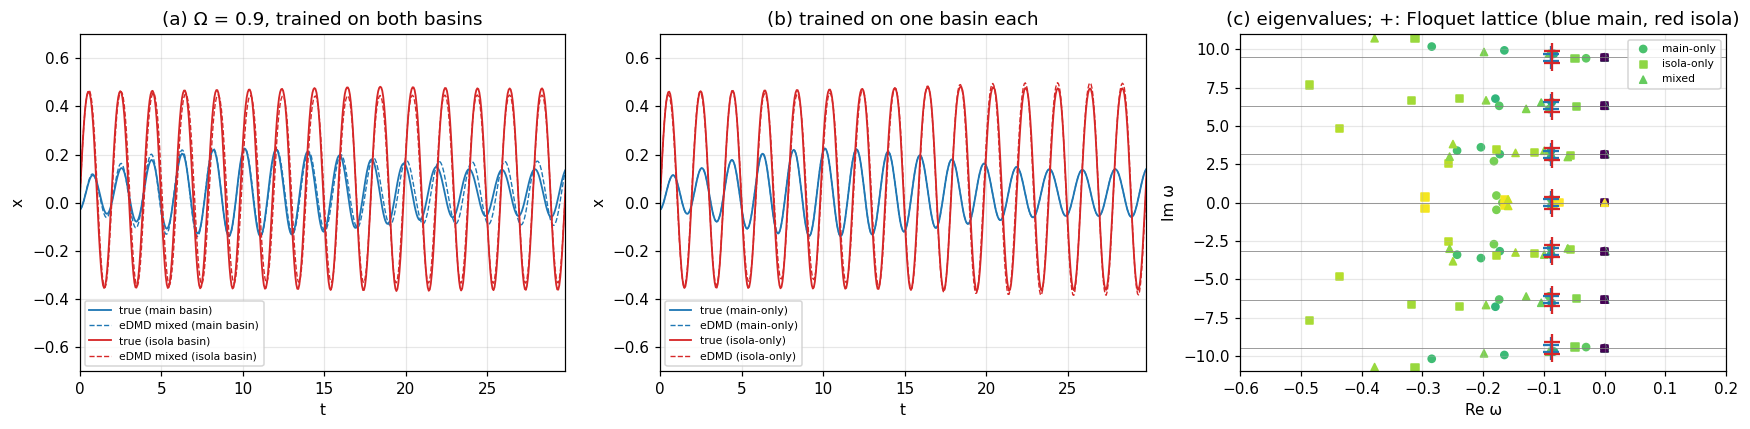

In [20]:
# 3-6. 경우 B — 끌림 영역별 초기조건 표본화 (풀인으로 가는 초기조건은 버림) -----------------------------------------------
OmB = 0.9; OdB = OmB*np.sqrt(PRM["w1sq"]); TB = 2*np.pi/OdB
hb2 = pd.read_csv(DATA_DIR / "Q_20_DC_1_AC_0.19_Ω_0.7_HBM_coeffs_branch02.csv"); hcols = [c for c in hb2.columns if c.startswith("hbm_")]
rowI = hb2[(hb2.stability == "stable") & ((hb2.Omega - OmB).abs() < 0.002)].iloc[0]; Ci = rowI[hcols].to_numpy()
x0I = Ci[0] + sum(Ci[2*k-1] for k in range(1, 14)); v0I = OdB*sum(k*Ci[2*k] for k in range(1, 14))
print(f"isola 주기해 (Ω={rowI.Omega:.4f}, A={rowI.A:.3f}, {rowI.stability}) 의 t=0 상태: x0={x0I:.4f}, ẋ0={v0I:.4f}")
rngB = np.random.default_rng(3)
def sample_basin(kind, m):
    # 후보를 적분해 최종 진폭으로 끌개를 판정: isola(0.4<A<0.5) / main(A<0.2); 풀인(발산)은 버림
    out = []
    while len(out) < m:
        X0 = (np.stack([x0I + rngB.uniform(-0.03, 0.03, 4*m), v0I + rngB.uniform(-0.08, 0.08, 4*m)]) if kind == "isola"
              else np.stack([rngB.uniform(-0.12, 0.12, 4*m), rngB.uniform(-0.4, 0.4, 4*m)]))
        S = rk4(X0, OdB, TB/32, 32*40); amp = np.abs(S[-96:, 0, :]).max(0)
        ok = (amp > 0.4) & (amp < 0.5) if kind == "isola" else (amp < 0.2); out += list(X0[:, ok].T)
    return np.array(out[:m]).T
ICm, ICi = sample_basin("main", 40), sample_basin("isola", 40)
SETS = {"main-only":  (ICm[:, :30], ICm[:, 30:]),
        "isola-only": (ICi[:, :30], ICi[:, 30:]),
        "mixed":      (np.hstack([ICm[:, :15], ICi[:, :15]]), np.hstack([ICm[:, 30:35], ICi[:, 30:35]]))}
dicB = DICTS_C["D4 +harmonics k<=3 × deg<=2 (46)"]
DB = {k: make_data(OmB, tr, te) for k, (tr, te) in SETS.items()}; RB = {k: run_edmd_cnt(DB[k], dicB) for k in SETS}

# Floquet 대조 (main: branch01, isola: branch02)
flB = pd.read_csv(DATA_DIR / "Q_20_DC_1_AC_0.19_Ω_0.7_HBM_coeffs_branch02_matlab_floquet_stability.csv"); rFi = flB.iloc[(flB.point_index - rowI.point_index).abs().argmin()]
rFm = flA.iloc[(flA.Omega - OmB).abs().argmin()]
fl_iso = np.log(rFi.mu1_abs)/TB + 1j*(OdB - np.arctan2(rFi.mu1_im, rFi.mu1_re)/TB)
fl_main = np.log(rFm.mu1_abs)/TB + 1j*(OdB - np.arctan2(rFm.mu1_im, rFm.mu1_re)/TB)
print(f"Hill–Floquet 격자점  main: {fl_main:.4f}   isola: {fl_iso:.4f}   (Ω_d = {OdB:.3f})")
rows = []
for k, R in RB.items():
    jm, ji = int(np.argmin(np.abs(R["omega"] - fl_main))), int(np.argmin(np.abs(R["omega"] - fl_iso)))
    e = R["pred_err_each"]; rows.append(dict(training=k, pred_err_main_ICs=(np.median(e[:5]) if k == "mixed" else (R["pred_err"] if k == "main-only" else np.nan)),
                                           pred_err_isola_ICs=(np.median(e[5:]) if k == "mixed" else (R["pred_err"] if k == "isola-only" else np.nan)),
                                           ω_near_main_Floquet=f"{R['omega'][jm]:.3f} (r={R['r'][jm]:.1e})", ω_near_isola_Floquet=f"{R['omega'][ji]:.3f} (r={R['r'][ji]:.1e})", n_r_lt_1e2=int(np.sum(R["r"] < 1e-2))))
display(pd.DataFrame(rows).set_index("training"))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
Dm = DB["mixed"]
for i, col, lab in [(0, "C0", "main basin"), (5, "C3", "isola basin")]:
    ax[0].plot(Dm["t"], Dm["S_te"][:, 0, i], color=col, lw=1.2, label=f"true ({lab})"); ax[0].plot(Dm["t"], RB["mixed"]["pred_x"][:, i], color=col, ls="--", lw=0.9, label=f"eDMD mixed ({lab})")
ax[0].set_xlim(0, 15*TB); ax[0].set_ylim(-0.7, 0.7); ax[0].set_xlabel("t"); ax[0].set_ylabel("x"); ax[0].set_title("(a) Ω = 0.9, trained on both basins"); ax[0].legend(fontsize=7)
for k, col in [("main-only", "C0"), ("isola-only", "C3")]:
    ax[1].plot(DB[k]["t"], DB[k]["S_te"][:, 0, 0], color=col, lw=1.2, label=f"true ({k})"); ax[1].plot(DB[k]["t"], RB[k]["pred_x"][:, 0], color=col, ls="--", lw=0.9, label=f"eDMD ({k})")
ax[1].set_xlim(0, 15*TB); ax[1].set_ylim(-0.7, 0.7); ax[1].set_xlabel("t"); ax[1].set_ylabel("x"); ax[1].set_title("(b) trained on one basin each"); ax[1].legend(fontsize=7)
for k, mk in [("main-only", "o"), ("isola-only", "s"), ("mixed", "^")]:
    R = RB[k]; ax[2].scatter(R["omega"].real, R["omega"].imag, c=np.maximum(R["r"], 1e-9), cmap="viridis", norm=norm, marker=mk, s=22, label=k)
for kk in range(-3, 4): ax[2].axhline(kk*OdB, color="gray", lw=0.5)
for f_, col in [(fl_main, "C0"), (fl_iso, "C3")]:
    for sgn in (1, -1):
        for kk in range(-3, 4): ax[2].plot(f_.real, sgn*(f_.imag - OdB) + kk*OdB, "+", color=col, ms=10, mew=1.5)
ax[2].set_xlim(-0.6, 0.2); ax[2].set_ylim(-11, 11); ax[2].set_xlabel("Re ω"); ax[2].set_ylabel("Im ω"); ax[2].set_title("(c) eigenvalues; +: Floquet lattice (blue main, red isola)"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()


**경우 B 해석 (§2.5 여러 끌개).**
* **main-only**: 경우 A와 같은 성공 — 예측 오차 $2\times10^{-3}$, Floquet 쌍 $-0.088+2.94i$가 main 가지의 Hill–Floquet 격자점과 일치.
* **isola-only**: 예측은 수 % 수준으로 따라가지만(가진 고조파가 정상상태 파형을 담아서) **Floquet 쌍이 잡히지 않는다**(잔차 0.3). isola 궤도는 진폭 0.477로 풀인 간극이 0.023 — $x/y_{PI}\approx0.95$라 전기력 급수가 거의 수렴하지 않고(W04에서 HBM 13차가 1.5 % 잔차를 남긴 것과 같은 자리), isola의 끌림 영역도 좁아(섭동 ±0.03이면 절반이 풀인) 과도 데이터 자체가 적다. **같은 사전이 끌개에 따라 "거의 닫힘"에서 "안 닫힘"으로 바뀐다.**
* **mixed**: 두 끌림 영역을 함께 학습하면 양쪽 모두 나빠진다 — main 영역 초기조건의 예측 오차가 $2\times10^{-3}$(단독)에서 $0.3$(혼합)으로 150배, isola 쪽도 4배 나빠지고 Floquet 쌍은 어느 쪽도 잡히지 않는다. 상태 $x$를 포함한 유한 선형계는 끌개가 하나뿐이라[B&K p. 297] 한 모델이 두 궤도를 동시에 담을 수 없고, 최소제곱은 진폭이 큰 isola 쪽에 치우쳐 main 쪽 예측이 틀어진다(그림 a). 감쇠 Duffing(노트 그림 14)과 같은 실패이며 사전을 키워도 고쳐지지 않는다. 풀인(발산)으로 가는 초기조건은 애초에 표본에서 버려야 했다 — 유계 끌개가 아닌 데이터는 어떤 사전으로도 담을 수 없다.
* 연구와의 연결: eDMD는 "끌개 하나의 근방"에서 Floquet 지수를 데이터만으로 돌려준다. 실험 과도응답에서 eDMD 고유값의 실수부가 0에 접근하는 것을 보면 안정성 경계(SN) 접근을 감지할 수 있지만, (i) 어느 끌개의 데이터인지 먼저 분리하고, (ii) isola처럼 풀인 근처의 끌개는 다항 사전 대신 지연좌표(HAVOK, 7주차)나 학습된 사전이 필요하다.

### 3-7. 요약
| 항목 | 결과 |
|---|---|
| 데이터 | CNT 공진기 운동방정식의 과도응답 (RK4, Δt = T/32, 40주기): 경우 A Ω=1.0 끌개 1개, 경우 B Ω=0.9 main·isola·풀인 공존 |
| 관측·사전 | $(x,\dot x,\cos\tau,\sin\tau)$; D1 DMD+가진(5) → D2 +다항 3차(12) → D3 +$\cos\tau,\sin\tau$×2차(22) → D4 +고조파 $k\le3$×2차(46) |
| 정확히 닫히는 것 | 가진 고조파 $ik\Omega_d$, 상수 — 잔차 $10^{-14}$ |
| Floquet 쌍 | eDMD $-0.088\pm3.397i$ (D4) ↔ Hill–Floquet $-0.088\pm3.397i$, Re $=-c/2$; 잔차 $10^{-2}$(D1–D3) → $2.6\times10^{-3}$(D4) |
| 닫히지 않는 항 | 가진 고조파 × 상태 (Floquet 좌표의 주기 변조) — 다항 차수나 전기력 급수가 아님; $K=4$에서 포화하는 $2.5\times10^{-3}$ 바닥은 유리함수 항의 "거의 닫힘" |
| 가짜 고유쌍 | 사전 크기의 절반 이상, $r_j>0.1$; 궤적 위 $\lvert\varphi\rvert$가 $e^{\mathrm{Re}\,\omega t}$를 따르지 않음 |
| 한계 (§2.5) | 여러 끌개: 혼합 학습 → main 예측 오차 150배 악화·Floquet 쌍 소실; 끌개별 학습 → main은 Floquet 복원($-0.088+2.94i$), isola는 풀인 근처라 다항 사전으로 안 닫힘(잔차 0.3) |
| 처방 | 끌림 영역별 학습; 가진 고조파 × 상태 항; 풀인 근처는 지연좌표(HAVOK)·학습 사전; ResDMD 잔차 검증 |


## AI 사용 명세

사용 도구: Claude (Anthropic). 노트북 구성·코드 초안·문제 3의 설계(가진계의 관측 벡터, Floquet 대조) 논의에 사용했고, 아래는 질문 로그와 교재(식 번호)와 대조해 확인·수정한 지점이다. 코드는 모두 직접 실행해 수치를 확인했다.

### 1. 질문 로그 — 노트북 구성

| # | 질문 | 교재와 대조해 확인·수정한 지점 |
|---|---|---|
| 1 | W06 과제 1·2·3을 앞 주차와 같은 구성(정리 → 문제 → 코드 → 결과)의 .ipynb로; 개인 탐구는 내 데이터로. | 과제 요구(사전 D1–D4, 표 5·그림 11, φλ 계수 비교, 손계산 예 0·2·4 검산, 문제 3의 사전 2가지 이상·가짜 가려내기·닫히지 않는 항·§2.5 한계)를 강의노트 25쪽과 대조. |
| 2 | eDMD를 numpy만으로 구현하려면 좌고유벡터와 잔차를 어떻게 계산하나? | `eig(A.T)`의 우고유벡터 = A의 좌고유벡터 [B&K (7.103)은 (7.98)의 전치]; 고유값 순서가 달라 λ로 짝을 맞춤. 잔차 (6)은 노트 그림 10 아래 식(ResDMD 정규화). |
| 3 | 상수함수(λ=1)의 잔차가 0/0이 되는데 어떻게 처리하나? | 분모 $\lvert\lambda-1\rvert$가 0 → 상수는 항상 참 고유함수이므로 $r=0$으로 표기하고 본문에 명시. |

### 2. 질문 로그 — 문제별 세부 질문과 확인 지점

**문제 1 (교재 예제 재현)**

| # | 질문 | 확인·수정한 지점 |
|---|---|---|
| 1-1 | D4 "가중 차수 $a+2c\le4$"가 정확히 어떤 단항식 9개인가? | $x_1^ax_2^c$에서 $x_2$를 2차로 센 것: $(a,c)\in\{(0,0),(1,0),(2,0),(3,0),(4,0),(0,1),(1,1),(2,1),(0,2)\}$ — 9개, 고유값 $p\mu+q\lambda$ 9개와 일대일. |
| 1-2 | 수치적분 대신 해석해로 데이터를 만들어도 되나? | (7.82)는 닫힌 해가 있으므로 해석해 사용 — 적분 오차가 섞이지 않아 D2·D4의 잔차 $10^{-8}$ 이하가 "사전의 닫힘"만 반영. |
| 1-3 | D1의 틀린 고유값 $-0.113$은 어디서 오나? | $x_2$의 변화율에 필요한 $x_1^2$을 $x_1,x_2$에 투영한 최소제곱 결과 — 데이터의 초기조건 분포에 따라 값이 달라짐(§2.3 D1 설명). |
| 1-4 | 좌고유벡터로 만든 φλ의 계수 정규화는? | $x_2$ 계수를 1로 나눔 → $x_1^2$ 계수 $-b=-1.111$ [B&K (7.84)]. |
| 1-5 | D3의 예측이 정확한데 왜 "실패"로 안 보나? | 예측(➂)은 D2 ⊂ D3이라 정확하지만 고유값 4개가 가짜 — 노트 표 5 "예측은 정확, 고유값 일부 가짜". 검증 세 가지가 모두 필요한 이유. |

**문제 2 (배포 풀이 오류 찾기)**

| # | 질문 | 확인·수정한 지점 |
|---|---|---|
| 2-1 | (7.83) 행렬의 (2,3) 성분 부호는? | $\dot x_2=\lambda x_2-\lambda x_1^2$ → $-\lambda$. 부호가 바뀌면 다른 계(차이 $O(1)$). |
| 2-2 | $b$의 부호가 틀리면 왜 기울기가 λ가 아니라 중간값이 되나? | $\varphi=x_2-bx_1^2$에 $e^{2\mu t}$ 성분 $(b_{true}-b)x_{10}^2e^{2\mu t}$가 남아 두 지수의 합 → $\log\lvert\varphi\rvert$가 직선이 아님(노트 그림 6c의 $x_2$와 같은 현상). |
| 2-3 | `TX \ TXp`와 `(TX \ TXp).'` 중 어느 것이 (7.98)인가? 고유값이 같은데 왜 문제인가? | 행 = 스냅샷이면 $\Theta(X)A\approx\Theta(X')$ → $y_{k+1}=A^Ty_k$. 전치해야 $A_Y$. 고유값은 같지만 고유벡터·예측·잔차가 다름 — 파일의 '검증' 줄 힌트. |
| 2-4 | 우고유벡터로 $\varphi=\Theta\xi$를 만들면 왜 잔차가 큰가? | (7.103)은 (7.98)의 전치: 사전 함수의 **계수**를 보내는 것은 $A_Y^T$ → 좌고유벡터. 우고유벡터는 모드(센서 공간의 벡터). 손계산 예 0의 $K=P^T$와 같은 이유. |
| 2-5 | $\Gamma$에 $\dot x$ 대신 $x$를 곱하면 왜 영공간이 사라지나? | $\nabla\theta\cdot x=(\text{차수})\theta$ (Euler 항등식)라 $\Gamma$가 $\Theta$의 열 척도 변환이 되어 full rank. $\nabla\theta\cdot\dot x$라야 $\mathcal K\theta$이고 λ=0의 영벡터가 $\tfrac43H$. |
| 2-6 | 손계산 예 4의 $K_{33}$이 0.9가 아니라 0.81인 이유는? | $x_1^2$의 다음 값 $=(0.9x_1)^2$ — 곱 고유함수의 고유값은 곱(이산) [B&K (7.71)]. 0.9면 데이터 행렬과 0.09 차이. |
| 2-7 | MATLAB의 `lift`, `edmd`, `koopman_residual` 없이 재현해도 되나? | 0.10의 numpy 도구(`lift_monomials`, `edmd`, 잔차 (6))로 대체. 난수가 달라 수치는 다르지만 수정 전후의 정성적 차이는 동일함을 본문에 명시. |

**문제 3 (CNT 공진기 eDMD)**

| # | 질문 | 확인·수정한 지점 |
|---|---|---|
| 3-1 | 주기 가진(비자율계)에 Koopman·eDMD를 어떻게 적용하나? | 가진 위상 $\tau=\Omega_dt$를 상태로 넣으면 $(\cos\tau,\sin\tau)$가 선형(회전)으로 닫힘 → 자율계로 확장. 가진 고조파 $ik\Omega_d$가 정확한 고유값이 됨(잔차 $10^{-14}$로 확인). |
| 3-2 | 주기궤도 근처의 Koopman 고유값이 무엇과 대응하나? | Floquet 지수 $\ln\mu/T$ (mod $i\Omega_d$) + 가진 고조파의 격자 [B&K (7.71)–(7.74) 격자]. 연구의 Hill–Floquet csv에서 환산해 eDMD 값과 일치 확인. |
| 3-3 | W02·W04처럼 HBM 주기해 데이터를 쓸 수는 없나? | HBM 해는 정상상태만 담아 과도(감쇠) 정보가 없음 — Koopman 고유값의 실수부를 보려면 과도응답이 필요 → 운동방정식을 시간 적분(RK4). 단 isola 초기조건과 Floquet 대조에는 HBM 데이터 사용. |
| 3-4 | 사전을 키워도 잔차가 $10^{-2}$에서 멈추는 이유는? | AI 초기 설명은 "비다항 전기력 $(y_{PI}-x)^{-0.68}$의 무한 급수"였으나, 데이터 범위에서 그 급수는 3차에서 0.4 %로 수렴하고 다항 차수를 5까지 올려도 잔차가 그대로라 기각. 가진 고조파 $\cos k\tau,\sin k\tau$ × 상태를 넣자 잔차가 10배 줄어 **Floquet 좌표의 주기 변조**가 원인임을 확인(3-5). Δt(T/16–T/128)를 바꿔도 잔차가 같음도 확인. |
| 3-5 | 물리 항 $V^2/(y_{PI}-x)^{0.68}$을 사전에 직접 넣으면 닫히나? | 안 닫힘 — 그 항의 변화율에 $\dot x\,V^2/g^{1.68}$, $\sin\tau\cdot V/g^{0.68}$이 또 필요(화살표가 밖으로 나감). 시험해 보니 잔차 $O(1)$로 오히려 나빠져 사전에서 제외. 주기 가진계의 Koopman 고유함수는 $\varphi\approx u(\tau)^T(x-x_p(\tau))$ 꼴이라 "물리 항"보다 "가진 고조파 × 상태"가 맞는 후보. |
| 3-6 | D1(DMD+가진)과 D2·D3의 예측 오차 차이가 작은데 eDMD의 이득은? | 끌개가 하나이고 과도가 $-c/2$ 감쇠로 지배돼 예측은 비슷; 이득은 올바른 항(가진 고조파 × 상태)을 넣은 D4에서만 10배로 나타남. 예측만으로 사전을 평가하면 안 된다는 §2.3의 교훈. |
| 3-7 | 가짜 고유쌍을 어떻게 가려내나? | 잔차 $r_j>0.1$ + 시험 궤적 위에서 $\lvert\varphi(x(t))\rvert$ vs $e^{\mathrm{Re}\,\omega t}$ (그림 12 방식). 가진 쌍은 수평선, Floquet 쌍은 $-c/2$ 감쇠선, 가짜는 어느 쪽도 아님. |
| 3-8 | Ω=0.9에서 isola 초기조건이 풀인으로 가는 경우가 있는데 어떻게 하나? | 후보 초기조건을 먼저 적분해 최종 진폭으로 끌개를 판정하고 풀인은 버리는 표본화(`sample_basin`). 섭동 ±0.03이면 약 절반이 풀인 — isola의 끌림 영역이 좁다는 것 자체가 결과. |
| 3-9 | 여러 끌개를 섞어 학습하면 왜 실패하나? isola만으로 학습하면 되나? | 상태 $x$를 포함한 유한 선형계는 끌개가 하나뿐 [B&K p. 297, Brunton 2016] → 한 궤도에 치우쳐 다른 영역의 예측이 틀어짐(노트 그림 14의 메커니즘). isola만으로 학습하면 예측은 되지만 Floquet 쌍은 안 잡힘 — 풀인 간극 0.023에서 전기력 급수가 수렴하지 않아 같은 사전이 "안 닫힘"으로 바뀜(W04의 HBM 13차 잔차 1.5 %와 같은 자리). |
| 3-10 | 이 결과가 연구(isola 논문)에 주는 시사점은? | eDMD 고유값 = 주기해 근방 Floquet 지수 → 실험 과도응답에서 isola 안정성(SN 접근)을 데이터로 감지 가능; 단 끌개별로 데이터를 분리해야 함. HAVOK(7주차)로 비다항 항 우회 검토. |

### 3. AI 답변 중 틀렸거나 보완한 지점

| # | AI의 초기 답 | 수정 |
|---|---|---|
| 1 | 잔차 바닥 $10^{-2}$의 원인을 "비다항 전기력의 무한 급수"로 설명 | 다항 차수 1→5에서 잔차가 그대로이고 급수는 3차에서 0.4 %로 수렴 → 기각. 가진 고조파 × 상태(Floquet 좌표의 주기 변조)로 정정하고 3-5에서 $K$ 훑기로 확인. |
| 2 | 물리 항 $V^2/g^{0.68}$을 사전에 넣은 D4 초안 | 잔차 $O(1)$로 악화 → 제외하고 이유(그 항의 변화율이 다시 사전 밖)를 명세 3-5에 기록. |
| 3 | 손계산 예 4의 좌고유벡터를 `eig(A.T)`의 열 순서 그대로 사용 | `eig(A)`와 `eig(A.T)`의 고유값 순서가 달라 짝이 틀림 → λ로 짝을 맞추는 코드로 수정. |
| 4 | 경우 B의 isola 초기조건을 섭동만으로 만들고 풀인 궤적을 거르지 않음 | 혼합 데이터에 발산 궤적 7개가 섞여 결과가 오염 → 최종 진폭으로 끌개를 판정해 풀인을 버리는 표본화로 수정. |
| 5 | 문제 1의 D1·D3 고유값을 노트의 수치($-0.113$, 가짜 위치)와 비교하려 함 | 사전 밖 성분의 투영값은 데이터(초기조건)에 따라 달라짐(노트 표 5 각주) → 개수와 잔차 범위만 비교하도록 수정. |
